<!-- # Create flux spectrum for given target
- Load all necessary ingredients
- Create model
- Fit model to data 
- Plot spectrum -->

In [127]:
import ROOT, glob, os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [128]:
dirDir= "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
figPath = dirDir + "figures/"
dataPath = dirDir + "data/"
dataPath2 = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/"
#dataFile = dataPath + "DmlNtup_Data_9years_FullPhotonData_AllSky.root"
dataFile = dataPath2 + "DmlNtup_Data_9years_AllSky_LeoVelocity.root"
beegfs_path = "/dpnc/beegfs/dampe/tryf/ForKimberly/"
exposurePath = beegfs_path + "exposureMaps_targets/"
resPath = dirDir + "results/"

target = "Vela"
exposurePath = exposurePath + target + "/"
figPath = figPath + target + "/" + "maxLikelihood/" 

os.makedirs(figPath, exist_ok=True)


In [129]:
def conv_lon_deg(target_lon):
    target_lon = np.where(target_lon > 180, target_lon - 360, target_lon)
    return target_lon

def conv_lon_rad(target_lon):
    target_lon = np.where(target_lon > np.pi, target_lon - 2*np.pi, target_lon)
    return target_lon

In [130]:
from matplotlib.colors import LogNorm

def plot_map(fig, ax, lon_edges, lat_edges, counts, energy, target_lon, target_lat, target_name="Target", norm=None):
    lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
    lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])

    lon_deg = np.rad2deg(lon_centers)
    lat_deg = np.rad2deg(lat_centers)

    lon_grid, lat_grid = np.meshgrid(lon_deg, lat_deg, indexing='ij')

    im = ax.pcolormesh(lon_grid, lat_grid, counts, cmap='viridis', shading='auto', norm=norm)
    ax.plot(target_lon, target_lat, 'rx', markersize=8, label=f'{target_name}')
    ax.xaxis.set_inverted(True)
    ax.legend(loc='upper right', fontsize=8)

    ax.set_xlabel('Galactic longitude [deg]', fontsize=10)
    ax.set_ylabel('Galactic latitude [deg]', fontsize=10)
    ax.set_aspect('auto')

    if energy == "all":
        ax.set_title(f'Count Map of {target_name} ROI at all energies', fontsize=10)
    else:
        ax.set_title(f'Count Map of {target_name} ROI at {energy:.3f} GeV', fontsize=10)

    return im

def plot_counts_map(fig, ax, lon_edges, lat_edges, counts, energy, target_lon, target_lat, target_name="Target"):

    im = plot_map(fig, ax, lon_edges, lat_edges, counts, energy, target_lon, target_lat, target_name)
    fig.colorbar(im, ax=ax, orientation='vertical', label='Counts')
    return im

def plot_exposure_map(fig, ax, lon_edges, lat_edges, exposure_map, energy, target_lon, target_lat, target_name="Target"):
    
    im = plot_map(fig, ax, lon_edges, lat_edges, exposure_map, energy, target_lon, target_lat, target_name)

    ax.set_title(f'Exposure map in {target_name} ROI at {energy:.3f} GeV', fontsize=10)

    fig.colorbar(im, ax=ax, orientation='vertical', label='Exposure [cm² s]')

    return im

def plot_giem_map(fig, ax, lon_edges, lat_edges, counts, energy, target_lon, target_lat, target_name="Target", convolved=False):
    im = plot_map(fig, ax, lon_edges, lat_edges, counts, energy, target_lon, target_lat, target_name, norm=LogNorm())
    fig.colorbar(im, ax=ax, orientation='vertical', label='Background level')
    title = f'GIEM map in {target_name} ROI at {energy:.3f} GeV'
    if convolved :
        title = "Convolved" + title
    ax.set_title(title)
    return im


<!-- ### Load Flight Data -->

In [131]:
tree = None
f = ROOT.TFile(dataFile, "READ") 

tree = f.Get("DmlNtup")
print(tree)
print(type(tree))
rdf = ROOT.RDataFrame(tree)
df = rdf.AsNumpy(["celestialcoordBest_2", "celestialcoordBest_3", "tt_bgoTotalEcorr_GeV"])
df = pd.DataFrame(df)

df = df.rename(columns={"celestialcoordBest_2" : "lon", "celestialcoordBest_3" : "lat", 
                        "tt_bgoTotalEcorr_GeV" : "energy"})

df['lon_deg'] = df['lon']*180/np.pi
print(f"Before lon processing : spans {df['lon_deg'].min()} deg to {df['lon_deg'].max()} deg")
print(f"Before lon processing : spans {df['lon'].min()} rad to {df['lon'].max()} rad")
df['lat_deg'] = df['lat']*180/np.pi
df['lon'] = conv_lon_rad(df['lon'])
print(f"After lon processing : spans {df['lon'].min()} rad to {df['lon'].max()} rad")

Name: DmlNtup Title: DmlNtup
<class cppyy.gbl.TTree at 0x1a205c70>
Before lon processing : spans 0.00018620734699823874 deg to 359.9997368103459 deg
Before lon processing : spans 3.2499312965228455e-06 rad to 6.2831807136535645 rad
After lon processing : spans -3.1415897051440638 rad to 3.141583204269409 rad


<!-- ### Load target coordinates -->

In [132]:
import os
import re
from astropy.coordinates import SkyCoord
from astropy import units as u

def parse_par_file(filename):
    """
    Parse a .par file and extract RAJ and DECJ values.
    
    Parameters:
    filename (str): Path to the .par file
    
    Returns:
    tuple: (raj_value, decj_value) or (None, None) if not found
    """
    raj_value = None
    decj_value = None
    
    try:
        with open(filename, 'r') as f:
            for line in f:
                line = line.strip()
                
                # Skip empty lines and comments
                if not line or line.startswith('#'):
                    continue
                
                # Split line into components
                parts = line.split()
                if len(parts) < 2:
                    continue
                
                parameter = parts[0].upper()
                
                # Extract RAJ value
                if parameter == 'RAJ':
                    # RAJ value is typically in format HH:MM:SS.ssss
                    raj_value = parts[1]
                
                # Extract DECJ value  
                elif parameter == 'DECJ':
                    # DECJ value is typically in format +/-DD:MM:SS.ssss
                    decj_value = parts[1]
    
    except FileNotFoundError:
        print(f"Error: Could not find file {filename}")
        return None, None
    except Exception as e:
        print(f"Error reading file {filename}: {e}")
        return None, None
    
    return raj_value, decj_value

def convert_ra_to_decimal(ra_str):
    """
    Convert RA string from HH:MM:SS.ssss format to decimal hours.
    
    Parameters:
    ra_str (str): RA in HH:MM:SS.ssss format
    
    Returns:
    float: RA in decimal hours
    """
    if ra_str is None:
        return None
    
    try:
        parts = ra_str.split(':')
        hours = float(parts[0])
        minutes = float(parts[1]) if len(parts) > 1 else 0
        seconds = float(parts[2]) if len(parts) > 2 else 0
        
        decimal_hours = hours + minutes/60.0 + seconds/3600.0
        return decimal_hours
    except (ValueError, IndexError):
        print(f"Error parsing RA: {ra_str}")
        return None

def convert_dec_to_decimal(dec_str):
    """
    Convert DEC string from +/-DD:MM:SS.ssss format to decimal degrees.
    
    Parameters:
    dec_str (str): DEC in +/-DD:MM:SS.ssss format
    
    Returns:
    float: DEC in decimal degrees
    """
    if dec_str is None:
        return None
    
    try:
        # Handle sign
        sign = 1
        if dec_str.startswith('+'):
            dec_str = dec_str[1:]
        elif dec_str.startswith('-'):
            sign = -1
            dec_str = dec_str[1:]
        
        parts = dec_str.split(':')
        degrees = float(parts[0])
        minutes = float(parts[1]) if len(parts) > 1 else 0
        seconds = float(parts[2]) if len(parts) > 2 else 0
        
        decimal_degrees = degrees + minutes/60.0 + seconds/3600.0
        return sign * decimal_degrees
    except (ValueError, IndexError):
        print(f"Error parsing DEC: {dec_str}")
        return None

# Main extraction code
parDirName = dirDir + f"data/{target}/"

# HERE you can enter your custom path to a .par file. Otherwise the script will look
# into data/{target} for a .par file
filename = None 

if filename is None:
    try:
        for file in os.listdir(parDirName[:-1]):
            if file.endswith(".par"):
                filename = os.path.join(parDirName, file)
                break
    except FileNotFoundError as e:
        print(f"Error: no par file found in subdirectory {parDirName}. Target: {target}")
        raise e

if filename is None:
    raise FileNotFoundError(f"No .par file found in {parDirName}")

# Extract RAJ and DECJ from the par file
raj_str, decj_str = parse_par_file(filename)

if raj_str is None or decj_str is None:
    print("Error: Could not find RAJ and/or DECJ in the .par file")
    print(f"RAJ: {raj_str}, DECJ: {decj_str}")
else:
    # Convert to decimal values
    ra_target = convert_ra_to_decimal(raj_str)
    dec_target = convert_dec_to_decimal(decj_str)
    
    print(f"RAJ: {ra_target} hours, DECJ: {dec_target} degrees")
    print(f"Original format - RAJ: {raj_str}, DECJ: {decj_str}")
    
    # Create SkyCoord object (same as original)
    if ra_target is not None and dec_target is not None:
        c = SkyCoord(ra=ra_target*u.hourangle, dec=dec_target*u.degree, frame='icrs')
        c = c.transform_to('galactic')
        print(f"Galactic coordinates: l={c.l}, b={c.b}")

RAJ: 8.589058747222223 hours, DECJ: -45.17635419444444 degrees
Original format - RAJ: 8:35:20.61149000, DECJ: -45:10:34.87510000
Galactic coordinates: l=263.5518314289383 deg, b=-2.7873123683789167 deg


<!-- ### Load exposure maps -->

In [133]:
# Find all subfolders in exposurePath that match the pattern "[energy]GeV"
energy_dirs = [d for d in os.listdir(exposurePath) if os.path.isdir(os.path.join(exposurePath, d)) and d.endswith("GeV")]

E_bin_centers = []
exposure_maps = {}

for ed in energy_dirs:
    # Extract the energy value from the folder name (e.g., "10GeV" -> 10.0)
    try:
        energy = float(ed.replace("GeV", ""))
    except ValueError:
        continue  # skip folders that don't match the pattern

    npz_path = os.path.join(exposurePath, ed, "summed_exposure_map.npz")
    if os.path.exists(npz_path):
        data = np.load(npz_path)
        # If the .npz contains only one array, get it; otherwise, keep the dict
        arr = data[list(data.keys())[0]] if len(data.files) == 1 else dict(data)
        E_bin_centers.append(energy)
        exposure_maps[energy] = arr

# Sort energies and exposure_maps by energy
E_bin_centers = np.array(sorted(E_bin_centers))

exposure_maps = {e: exposure_maps[e] for e in E_bin_centers}

lon_edges = exposure_maps[E_bin_centers[0]]['lon_edges']
lat_edges = exposure_maps[E_bin_centers[0]]['lat_edges']

exposure_maps = {e: exposure_maps[e]['exposure_map'] for e in E_bin_centers}

verbose = True
vverbose = False

if verbose:
    print(f"lon edges: {lon_edges} rad")
    print(f"lon edges: {np.rad2deg(lon_edges)} deg")
    print(f"lat edges: {lat_edges} rad")
    print(f"lat edges: {np.rad2deg(lat_edges)} deg")
    if vverbose:
        print(f"Exposure maps :{exposure_maps}")

lon edges: [-1.71914931 -1.71696765 -1.71478599 -1.71260433 -1.71042267 -1.70824101
 -1.70605934 -1.70387768 -1.70169602 -1.69951436 -1.6973327  -1.69515104
 -1.69296937 -1.69078771 -1.68860605 -1.68642439 -1.68424273 -1.68206107
 -1.67987941 -1.67769774 -1.67551608 -1.67333442 -1.67115276 -1.6689711
 -1.66678944 -1.66460777 -1.66242611 -1.66024445 -1.65806279 -1.65588113
 -1.65369947 -1.6515178  -1.64933614 -1.64715448] rad
lon edges: [-98.5   -98.375 -98.25  -98.125 -98.    -97.875 -97.75  -97.625 -97.5
 -97.375 -97.25  -97.125 -97.    -96.875 -96.75  -96.625 -96.5   -96.375
 -96.25  -96.125 -96.    -95.875 -95.75  -95.625 -95.5   -95.375 -95.25
 -95.125 -95.    -94.875 -94.75  -94.625 -94.5   -94.375] deg
lat edges: [-0.0850848  -0.08290314 -0.08072148 -0.07853982 -0.07635815 -0.07417649
 -0.07199483 -0.06981317 -0.06763151 -0.06544985 -0.06326819 -0.06108652
 -0.05890486 -0.0567232  -0.05454154 -0.05235988 -0.05017822 -0.04799655
 -0.04581489 -0.04363323 -0.04145157 -0.03926991 -0.

<!-- ### Filter flight data to ROI -->

In [134]:
df = df.loc[(df['lon'] >= lon_edges[0]) & (df['lon'] < lon_edges[-1]) & (df['lat'] >= lat_edges[0]) & (df['lat'] < lat_edges[-1])]

if verbose :
    print(f"After lon/lat processing : lon spans {df['lon_deg'].min()} deg to {df['lon_deg'].max()} deg")
    print(f"After lon/lat processing : lat spans {df['lat_deg'].min()} deg to {df['lat_deg'].max()} deg")
    print(f"Kind recall : target coordinates: l={c.l}, b={c.b}")
    print(f"Number of events in ROI: {len(df)}")

After lon/lat processing : lon spans 261.5004586385681 deg to 265.6236799159647 deg
After lon/lat processing : lat spans -4.871115465568789 deg to -0.7520440617014835 deg
Kind recall : target coordinates: l=263.5518314289383 deg, b=-2.7873123683789167 deg
Number of events in ROI: 7522


In [135]:
counts, _, _ = np.histogram2d(
    df['lon'], df['lat'], bins=[lon_edges, lat_edges]
)


Target lon: -96.44816857106167 deg


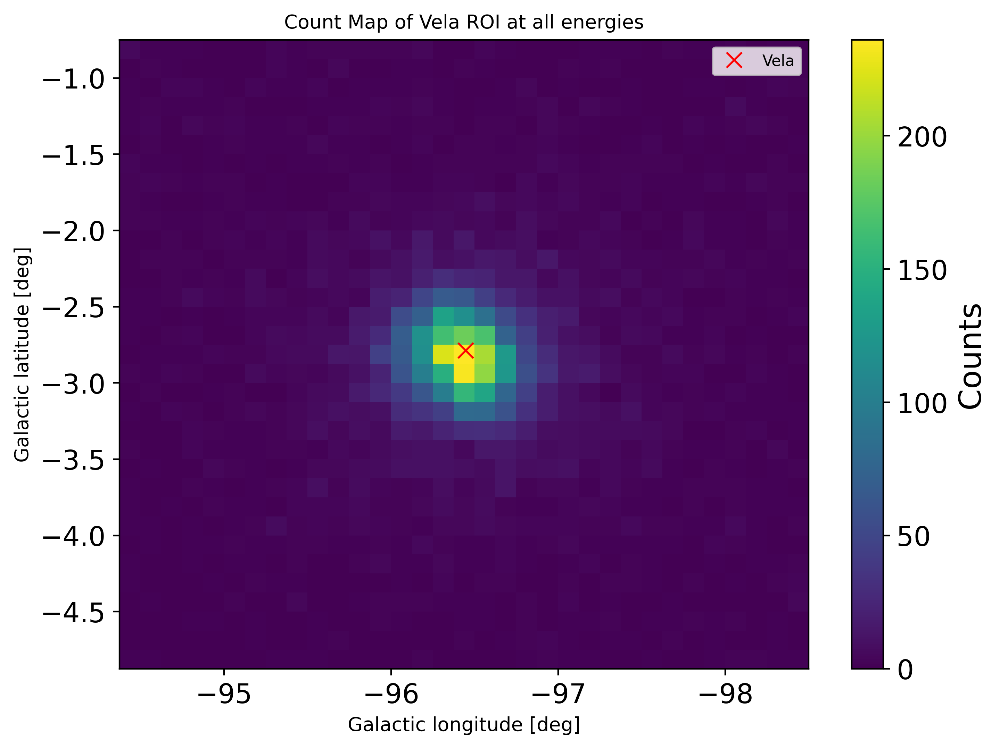

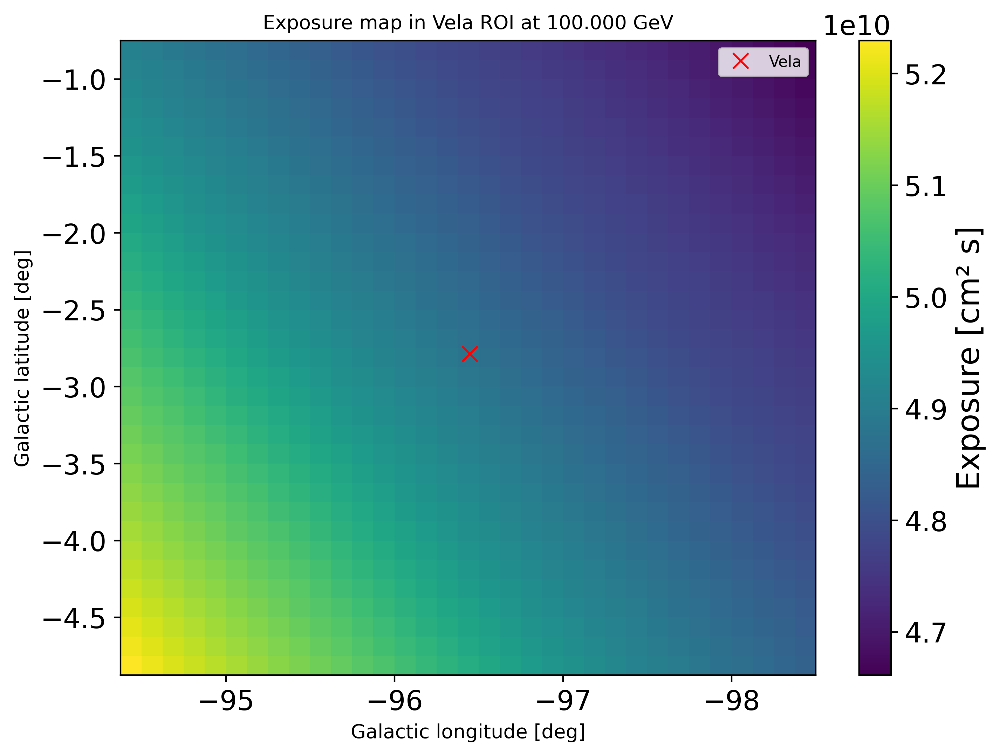

In [136]:

target_lon = c.l.deg % 360
target_lon = conv_lon_deg(target_lon)
print(f"Target lon: {target_lon} deg")
target_lat = c.b.deg

fig_c, ax_c = plt.subplots(figsize=(8, 6))
fig_e, ax_e = plt.subplots(figsize=(8, 6))

im_c = plot_counts_map(fig_c, ax_c, lon_edges, lat_edges, counts, 'all', target_lon, target_lat, target_name=target)
im_e = plot_exposure_map(fig_e, ax_e, lon_edges, lat_edges, exposure_maps[E_bin_centers[11]], E_bin_centers[11], target_lon, target_lat, target_name=target)

<!-- ### Slice flight data in energy bins -->

In [137]:
PATH_GIEM_BINS = "/home/users/l/lebrun/results/all_bins_GIEM.npz"
BINS_NPZ = np.load(PATH_GIEM_BINS)
ENERGY_BINS_EDGES = BINS_NPZ['E_bins_edge']
ENERGY_BINS_CENTERS = np.sqrt(ENERGY_BINS_EDGES[:-1] * ENERGY_BINS_EDGES[1:])  # GeV

print(f"Energy bins edges: {ENERGY_BINS_EDGES}")
print(f"Energy bins centers: {ENERGY_BINS_CENTERS}")
print(f"DEBUG : energy bins centers : {E_bin_centers}")

dfs = [df.loc[(df['energy'] >= ENERGY_BINS_EDGES[i]) & (df['energy'] < ENERGY_BINS_EDGES[i+1])] for i in range(len(ENERGY_BINS_EDGES)-1)]

PLOT_THIS = False

if PLOT_THIS:
    n_bins = len(ENERGY_BINS_CENTERS)
    ncols = 5  # for example
    nrows = (n_bins + ncols - 1) // ncols  # ceil division

    # Big figure for counts
    fig_counts, axs_counts = plt.subplots(nrows, ncols, figsize=(8*ncols, 6*nrows), constrained_layout=True)
    axs_counts = axs_counts.flatten()

    # Big figure for exposure
    fig_exposure, axs_exposure = plt.subplots(nrows, ncols, figsize=(8*ncols, 6*nrows), constrained_layout=True)
    axs_exposure = axs_exposure.flatten()

    for i, df_slice in enumerate(dfs):

        # Exposure map
        exposure = exposure_maps[E_bin_centers[i]]  
        im_exposure = plot_exposure_map( fig_exposure,
            axs_exposure[i], lon_edges, lat_edges, exposure,
            ENERGY_BINS_CENTERS[i], target_lon, target_lat, target_name=target
        )

        if len(df_slice) == 0:
            print(f"Energy bin {ENERGY_BINS_CENTERS[i]} GeV has no events.")
            
        
        counts, _, _ = np.histogram2d(
            df_slice['lon'], df_slice['lat'], bins=[lon_edges, lat_edges]
        )

        im_counts = plot_counts_map( fig_counts,
            axs_counts[i], lon_edges, lat_edges, counts,
            ENERGY_BINS_CENTERS[i], target_lon, target_lat, target_name=target
        )

        

    # Colorbar for counts
    # fig_counts.colorbar(im_counts, ax=axs_counts.tolist(), orientation='vertical', label='Counts')
    fig_counts.suptitle(f'Counts Maps of {target}', fontsize=16)
    fig_counts.savefig(figPath + "counts_maps_grid.png")
    fig_counts.savefig(figPath + "counts_maps_grid.eps", format='eps')

    # Colorbar for exposure
    # fig_exposure.colorbar(im_exposure, ax=axs_exposure.tolist(), orientation='vertical', label='Exposure [cm² s]')
    fig_exposure.suptitle(f'Exposure Maps of {target}', fontsize=16)
    fig_exposure.savefig(figPath + "exposure_maps_grid.png")
    fig_exposure.savefig(figPath + "exposure_maps_grid.eps", format='eps')

    # # Save or show
    # fig_counts.savefig("counts_maps_grid.png", dpi=300)
    # fig_exposure.savefig("exposure_maps_grid.png", dpi=300)
    plt.show()

Energy bins edges: [1.01858927e+00 1.32381626e+00 1.72050654e+00 2.23606768e+00
 2.90612012e+00 3.77695820e+00 5.59609532e+00 9.45240534e+00
 1.59661267e+01 2.69685007e+01 4.55526908e+01 7.69433815e+01
 1.29965626e+02 2.19525884e+02 3.70802769e+02 6.26325656e+02
 1.05793122e+03 1.78695933e+03 3.01836600e+03 5.09834398e+03
 8.61164993e+03]
Energy bins centers: [1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.59741428e+00 7.27300222e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999736e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37494730e+03 2.32243348e+03 3.92283930e+03 6.62609641e+03]
DEBUG : energy bins centers : [1.161000e+00 1.509000e+00 1.961000e+00 2.549000e+00 3.313000e+00
 4.597000e+00 7.273000e+00 1.228500e+01 2.075000e+01 3.505000e+01
 5.920300e+01 1.000000e+02 1.689110e+02 2.853080e+02 4.819160e+02
 8.140080e+02 1.374947e+03 2.322433e+03 3.922839e+03 6.626096e+03]


<!-- ### Load observing time map -->

In [138]:
obsTime_path = beegfs_path + "obsTime/" + target + f"/obs_time_{target}.npz"
obsTime = np.load(obsTime_path)

hist_obsTime = obsTime['histogram']
theta_bins_edge = obsTime['theta_edges']
phi_bins_edge = obsTime['phi_edges']

In [139]:
def plot_obsTime(histogram2d, theta_bins_edge, phi_bins_edge, target, figName=None):
    plt.figure(figsize=(8, 6))

    # Meshgrid of bin edges (assumes you have global theta_bins_edge and phi_bins_edge)
    phi_grid, theta_grid = np.meshgrid(phi_bins_edge, theta_bins_edge)

    # Plot as 2D colormap
    pcm = plt.pcolormesh(phi_grid, theta_grid, histogram2d, shading='auto', cmap='viridis')

    plt.xlabel(r'$\phi$ [deg]')
    plt.ylabel(r'$\cos(\theta)$')
    plt.title(f'2D Observation Distribution of {target} : 9 years')
    cbar = plt.colorbar(pcm, label='Observing Time [s]')
    plt.tight_layout()
    if figName :
        plt.savefig(figName)
    else:
        plt.show()

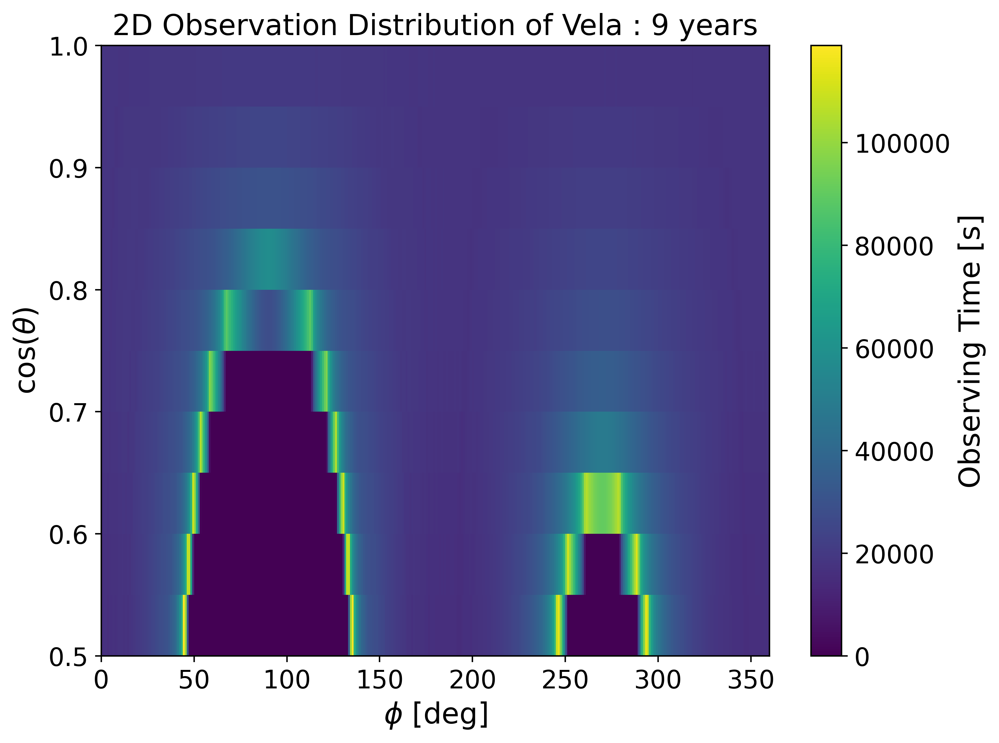

In [140]:
PLOT_THIS = True

if PLOT_THIS:
    plot_obsTime(hist_obsTime, theta_bins_edge, phi_bins_edge, target, figName=figPath+"obsT_vela.eps")

<!-- ### Load PSF -->

In [141]:
verbose = False

PSF_path = resPath + "PSF/exp0.0/script/fit_DK_params_all_bins.csv"
PSF_df = pd.read_csv(PSF_path)
if verbose:
    print(PSF_df.head())

PSF_infos_path = resPath + "PSF/exp0.0/script/infos_bins.npz"
PSF_infos = np.load(PSF_infos_path)

if 'E_bins_edge' in PSF_infos:
    PSF_E_bins_edge = PSF_infos['E_bins_edge']
    PSF_theta_bins_edge = PSF_infos['theta_bins_edge']
    PSF_E_bins_center = PSF_infos['E_bins_center']
    PSF_theta_bins_center = PSF_infos['theta_bins_center']
    if verbose :
        print(f"E_bins_edge: {PSF_E_bins_edge}")
        print(f"theta_bins_edge: {PSF_theta_bins_edge}")
        print(f"E_bins_center: {PSF_E_bins_center}")
        print(f"theta_bins_center: {PSF_theta_bins_center}")

<!-- ### Define exposure-weighted PSF -->

In [142]:
Sp_path = resPath + "PSF/exp0.0/script/resolution_per_bin_w.csv"
resolution_per_bin = pd.read_csv(Sp_path)
verbose = True
if verbose:
    print(resolution_per_bin)

    E_bin  theta_bin  angular_resolution
0       0          0            0.460173
1       0          1            0.711977
2       0          2            0.629419
3       0          3            0.572459
4       0          4            0.519339
5       1          0            0.765920
6       1          1            0.591159
7       1          2            0.427707
8       1          3            0.349095
9       1          4            0.318454
10      2          0            1.367630
11      2          1            0.519322
12      2          2            0.276029
13      2          3            0.202226
14      2          4            0.194648
15      3          0            1.554878
16      3          1            0.568165
17      3          2            0.184326
18      3          3            0.136843
19      3          4            0.125133
20      4          0            1.577278
21      4          1            0.389967
22      4          2            0.125694
23      4       

In [143]:

# === Model functions ===
def king(xp, sigma, gamma):
    factor1 = 1 / (2 * np.pi * sigma * sigma)
    factor2 = (1 - 1 / gamma)
    factor3 = (1 + 0.5 * (1 / gamma) * ((xp / sigma) ** 2)) ** (-gamma)
    return factor1 * factor2 * factor3

def x_king(xp, sigma, gamma):
    return xp * king(xp, sigma, gamma)

def double_x_King(xp, A, F, sigma_c, gamma_c, sigma_t, gamma_t):
    """Full double King model with x factor."""
    return 2 * np.pi * A * (F * x_king(xp, sigma_c, gamma_c) +
                (1 - F) * x_king(xp, sigma_t, gamma_t)) 

def doubleKing(xp, A, F, sigma_c, gamma_c, sigma_t, gamma_t):
    """Full double King model."""
    return A * (F * king(xp, sigma_c, gamma_c) +
                (1 - F) * king(xp, sigma_t, gamma_t))  

def PSF(x, E, cosTheta, verbose=False):
    """
    Vectorized PSF function.
    Supports array-like xp and cosTheta.
    """
    
    x = np.atleast_1d(x)
    E = np.atleast_1d(E)
    cosTheta = np.atleast_1d(cosTheta)

    # Create grid for broadcasting
    x_grid, cosTheta_grid = np.meshgrid(x, cosTheta, indexing='ij')
    E_grid = np.broadcast_to(E, cosTheta_grid.shape)  # shape (n_x, n_theta)

    if verbose:
        print(f"PSF: x_grid.shape={x_grid.shape}, cosTheta_grid.shape={cosTheta_grid.shape}")

    # Determine (E, cosTheta) bins
    E_bin = np.digitize(E_grid, PSF_E_bins_edge) - 1
    theta_bin = np.digitize(cosTheta_grid, PSF_theta_bins_edge) - 1

    E_bin = np.clip(E_bin, 0, len(PSF_E_bins_edge) - 2)
    theta_bin = np.clip(theta_bin, 0, len(PSF_theta_bins_edge) - 2)

    # Fetch Sp from resolution_per_bin
    indices = pd.MultiIndex.from_arrays([E_bin.flatten(), theta_bin.flatten()],
                                        names=('E_bin', 'theta_bin'))
    Sp_flat = resolution_per_bin.set_index(['E_bin', 'theta_bin']) \
                                .reindex(indices)['angular_resolution'].values
    Sp = Sp_flat.reshape(x_grid.shape)

    if verbose:
        print(f"Sp.shape={Sp.shape}, min(Sp)={Sp.min()}, max(Sp)={Sp.max()}")

    # Compute normalized deviation xp
    xp_grid = x_grid / Sp
    PSF_params = PSF_df.set_index(['E_bin', 'theta_bin']).reindex(indices).reset_index()

    if PSF_params.isnull().values.any():
        if verbose:
            print("Warning: Missing PSF parameters detected.")
        PSF_params.fillna(0, inplace=True)

    # Reshape parameters
    shape = xp_grid.shape
    A_c = PSF_params['A_c'].values.reshape(shape)
    sigma_c = PSF_params['sigma_c'].values.reshape(shape)
    gamma_c = PSF_params['gamma_c'].values.reshape(shape)
    A_t = PSF_params['A_t'].values.reshape(shape)
    sigma_t = PSF_params['sigma_t'].values.reshape(shape)
    gamma_t = PSF_params['gamma_t'].values.reshape(shape)

    A_tot = A_c + A_t
    F = np.divide(A_c, A_tot, out=np.zeros_like(A_c), where=A_tot != 0)

    # Compute PSF
    psf_vals = doubleKing(xp_grid, A_tot, F, sigma_c, gamma_c, sigma_t, gamma_t)

    return psf_vals.squeeze()  # shape (n_xp, n_theta)


PSF: x_grid.shape=(1000, 1), cosTheta_grid.shape=(1000, 1)
Sp.shape=(1000, 1), min(Sp)=0.6294190706666386, max(Sp)=0.6294190706666386


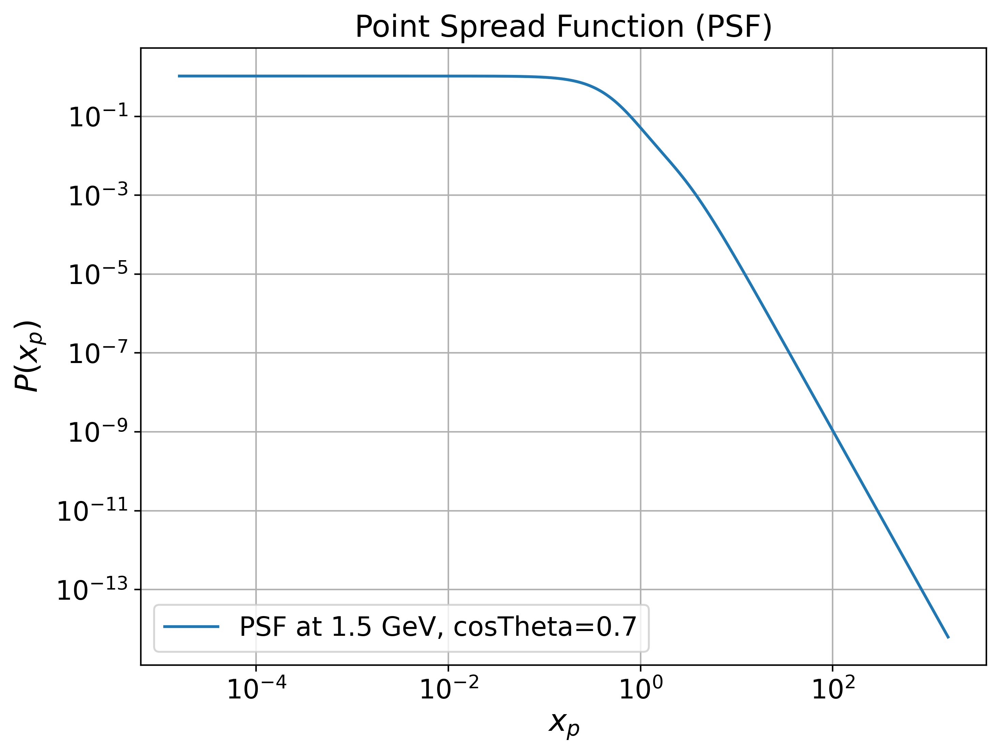

Integral of PSF: 0.43945481310558066


In [144]:
# TEST of PSF function
def test_psf():
    e = 1.5  # GeV
    cosTheta = 0.7

    x = np.logspace(-5, 3, 1000)  # Example range for PSF
    E_bin = np.digitize(e, PSF_E_bins_edge) - 1
    theta_bin = np.digitize(cosTheta, PSF_theta_bins_edge) - 1

    E_bin = np.clip(E_bin, 0, len(PSF_E_bins_edge) - 2)
    theta_bin = np.clip(theta_bin, 0, len(PSF_theta_bins_edge) - 2)

    Sp_df = resolution_per_bin.set_index(['E_bin', 'theta_bin'])
    Sp = Sp_df.loc[(E_bin, theta_bin), 'angular_resolution']

    xp = x / Sp

    psf_values = PSF(x, e, cosTheta, verbose=True)
    plt.figure(figsize=(8, 6))
    plt.plot(xp, psf_values, label=f'PSF at {e} GeV, cosTheta={cosTheta}')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('$x_p$')
    plt.ylabel('$P(x_p)$')
    plt.title('Point Spread Function (PSF)')
    plt.legend()
    plt.grid()
    plt.show()

    # Integrate to check int(psf) = 1
    integral = np.trapz(psf_values, xp)
    print(f"Integral of PSF: {integral}")   

# Uncomment to run the test
test_psf()

In [145]:
def load_effArea(path_effArea):
   
    effArea_npz = np.load(path_effArea)
    effArea_table = effArea_npz['effArea'] # Shape (n_E_bins, n_costheta_bins, n_phi_bins) ~ (20, 10, 360)

    effArea_E_bins_edge = effArea_npz['E_bins_edge']
    effArea_E_bins_center = np.sqrt(effArea_E_bins_edge[:-1] * effArea_E_bins_edge[1:])  # GeV

    effArea_theta_bins_edge = effArea_npz['theta_bins_edge']
    effArea_phi_bins_edge = effArea_npz['phi_bins_edge']

    return effArea_table, effArea_E_bins_edge, effArea_E_bins_center, effArea_theta_bins_edge, effArea_phi_bins_edge

effArea_path = "/home/users/l/lebrun/results/effArea/effectiveArea_weighted.npz"
effArea_table, effArea_E_bins_edge, effArea_E_bins_center, effArea_theta_bins_edge, effArea_phi_bins_edge = load_effArea(effArea_path)

effArea_theta_bins_center = 0.5*(effArea_theta_bins_edge[:-1] + effArea_theta_bins_edge[1:])
verbose = False
if verbose:
    print(f"DEBUG : effArea_E_bins_edge : {effArea_E_bins_edge}")
    print(f"DEBUG : effArea_E_bins_center : {effArea_E_bins_center}")
    print(f"DEBUG : effArea_theta_bins_center : {effArea_theta_bins_center}")
    print(f"Shape of effective area table: {effArea_table.shape}")
    print(f" Shape of obsTime: {hist_obsTime.shape}")

In [146]:
def PSF_bar(x, E, effArea_table=effArea_table, hist_obsTime=hist_obsTime, verbose=False):
    """
    Exposure-weighted PSF, fully vectorized version with solid angle correction.

    Parameters:
    ----------
    xp : array-like
        Positions where PSF is computed, shape arbitrary.
    E : float
        Photon energy.
    effArea_table : ndarray
        Effective area, shape (n_E_bins, n_theta_bins, n_phi_bins).
    hist_obsTime : ndarray
        Observing time, shape (n_theta_bins, n_phi_bins).
    verbose : bool
        Print debug info.

    Returns:
    -------
    ndarray
        Exposure-weighted PSF evaluated at each xp, same shape as xp.
    """
    # Find energy bin index
    E_bin = np.digitize(E, effArea_E_bins_edge) - 1
    if E_bin < 0 or E_bin >= len(effArea_E_bins_edge) - 1:
        if verbose:
            print(f"E={E} out of range, returning zeros")
        return np.zeros_like(x, dtype=float)

    effArea = effArea_table[E_bin, :, :]  # shape (n_theta_bins, n_phi_bins)

    # Flatten xp for vectorized computation
    x_flat = x.flatten()

    # Precompute dcosTheta and solid angle per (theta, phi) bin
    cosTheta_edges = effArea_theta_bins_edge  # len n_theta_bins+1
    dcosTheta = cosTheta_edges[1:] - cosTheta_edges[:-1]  # len n_theta_bins
    cosTheta_centers = 0.5 * (cosTheta_edges[:-1] + cosTheta_edges[1:])  # n_theta_bins

    dphi = np.deg2rad(effArea_phi_bins_edge[1] - effArea_phi_bins_edge[0])  # assume uniform phi bins
    solid_angle_per_bin = np.outer(dcosTheta, np.full(effArea.shape[1], dphi))  # shape (n_theta_bins, n_phi_bins)

    # Total solid angle should sum to 4*pi (sanity check)
    if verbose:
        total_solid_angle = np.sum(solid_angle_per_bin)
        print(f"Total solid angle covered: {total_solid_angle:.6f} sr (should be ~π = {np.pi:.6f} sr)")

    # Compute PSF at xp for all cosTheta bin centers (broadcasting)
    psf_vals_centers = PSF(x_flat, E, cosTheta_centers)  # shape (n_xp, n_theta_bins)

    # Expand to (n_xp, n_theta_bins, n_phi_bins) for weighting
    psf_vals_expanded = np.repeat(psf_vals_centers[:, :, np.newaxis], effArea.shape[1], axis=2)

    # Effective weights = effArea * obsTime * solid angle
    effective_weights = effArea * hist_obsTime * solid_angle_per_bin  # shape (n_theta_bins, n_phi_bins)

    # Numerator: weighted sum over (theta, phi)
    numerator = np.sum(psf_vals_expanded * effective_weights, axis=(1, 2))  # shape (n_xp,)

    # Denominator: total exposure weighted solid angle
    denominator = np.sum(effective_weights)  # scalar

    if denominator == 0:
        if verbose:
            print("Denominator is zero, returning zeros")
        return np.zeros_like(x)

    if verbose:
        print(f"E={E}, denominator={denominator}")
        print(f"Numerator shape={numerator.shape}, min={numerator.min()}, max={numerator.max()}")

    # Reshape numerator back to original xp shape and normalize
    return (numerator / denominator).reshape(x.shape)


Total solid angle covered: 3.141593 sr (should be ~π = 3.141593 sr)
E=1.3, denominator=21162.017064576758
Numerator shape=(1000,), min=262.7551912265345, max=22015.89958113832


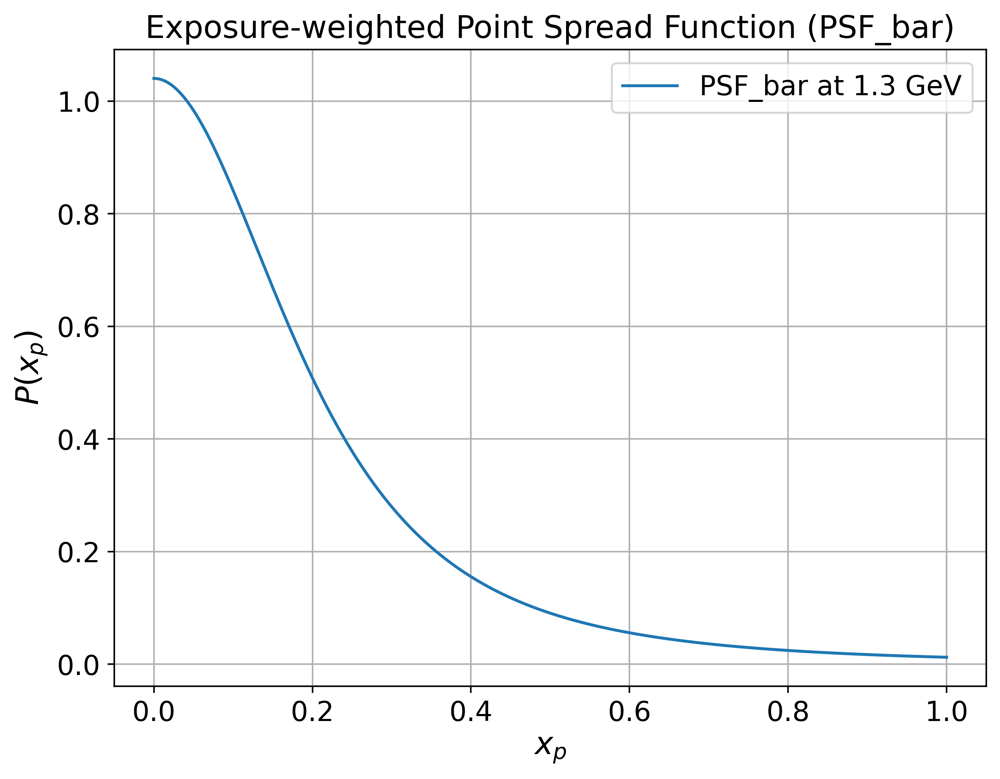

Integral of PSF_bar: 0.4029001927361231


In [147]:
# TEST of PSF_bar function
def test_psf_bar():
    e = 1.3  # GeV

    cosTheta = 0.7

    x = np.logspace(-5, 0, 1000)  # Example range for PSF
    E_bin = np.digitize(e, PSF_E_bins_edge) - 1
    theta_bin = np.digitize(cosTheta, PSF_theta_bins_edge) - 1

    E_bin = np.clip(E_bin, 0, len(PSF_E_bins_edge) - 2)
    theta_bin = np.clip(theta_bin, 0, len(PSF_theta_bins_edge) - 2)

    Sp_df = resolution_per_bin.set_index(['E_bin', 'theta_bin'])
    Sp = Sp_df.loc[(E_bin, theta_bin), 'angular_resolution']

    xp = x / Sp

    psf_values = PSF_bar(x, e, effArea_table, hist_obsTime, verbose=True)
    plt.figure(figsize=(8, 6))
    plt.plot(x, psf_values, label=f'PSF_bar at {e} GeV')
    plt.xscale('linear')
    plt.yscale('linear')
    plt.xlabel('$x_p$')
    plt.ylabel('$P(x_p)$')
    plt.title('Exposure-weighted Point Spread Function (PSF_bar)')
    plt.legend()
    plt.grid()
    plt.show()

    # Integrate to check int(psf) = 1
    integral = np.trapz(psf_values, xp)
    print(f"Integral of PSF_bar: {integral}")   

# Uncomment to run the test
test_psf_bar()

<!-- ## Define sources model -->

<!-- ### Load GIEM -->

In [148]:
GIEM_path = "/home/users/l/lebrun/results/giem_extrapolated.npz"
giem = np.load(GIEM_path)

giem_data = giem['data']
giem_energies = giem['energies']

PATH_GIEM_BINS = "/home/users/l/lebrun/results/all_bins_GIEM.npz"
BINS_NPZ = np.load(PATH_GIEM_BINS)
# Flip longitude axis
giem_lon_edges = BINS_NPZ['lon_edges']
giem_lat_edges = BINS_NPZ['lat_edges']
giem_data = giem_data[:, :, ::-1]


In [149]:

verbose = True
if verbose :
    print(f"GIEM data shape : {giem_data.shape}")
    print(f"GIEM energies : {giem_energies}")
    print(f"To compare with : exposure energies {E_bin_centers}")

min_E_idx = np.digitize(E_bin_centers[0], giem_energies)
giem_energies = giem_energies[min_E_idx:]
giem_data = giem_data[min_E_idx:]
if verbose:
    print(f"New giem_energies shape : {giem_energies.shape}")
    print(f"New giem_data shape : {giem_data.shape}")

GIEM data shape : (32, 1441, 2880)
GIEM energies : [5.00000000e-02 6.49828300e-02 8.44553639e-02 1.09762971e-01
 1.42654170e-01 1.85401433e-01 2.40958196e-01 3.13162910e-01
 4.07004243e-01 5.28965751e-01 6.87473830e-01 8.93479900e-01
 1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.30582611e+00 7.27300221e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999737e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37286811e+03 2.31541487e+03 3.90506996e+03 6.58610755e+03]
To compare with : exposure energies [1.161000e+00 1.509000e+00 1.961000e+00 2.549000e+00 3.313000e+00
 4.597000e+00 7.273000e+00 1.228500e+01 2.075000e+01 3.505000e+01
 5.920300e+01 1.000000e+02 1.689110e+02 2.853080e+02 4.819160e+02
 8.140080e+02 1.374947e+03 2.322433e+03 3.922839e+03 6.626096e+03]
New giem_energies shape : (20,)
New giem_data shape : (20, 1441, 2880)


In [150]:
roi_lon_edges = lon_edges  # shape (Nlon+1,)
roi_lat_edges = lat_edges  # shape (Nlat+1,)

# Find index ranges for cropping
lon_start_idx = np.searchsorted(giem_lon_edges, roi_lon_edges[0], side='left')
lon_end_idx   = np.searchsorted(giem_lon_edges, roi_lon_edges[-1], side='right') - 1

lat_start_idx = np.searchsorted(giem_lat_edges, roi_lat_edges[0], side='left')
lat_end_idx   = np.searchsorted(giem_lat_edges, roi_lat_edges[-1], side='right') - 1

# Crop the data cube
cropped_giem_data = giem_data[:, lat_start_idx:lat_end_idx, lon_start_idx:lon_end_idx]

# Get corresponding edges for the cropped region
cropped_lon_edges = giem_lon_edges[lon_start_idx:lon_end_idx + 1]
cropped_lat_edges = giem_lat_edges[lat_start_idx:lat_end_idx + 1]

Cropped lon edges : [-1.71914931 -1.71696765 -1.71478599 -1.71260433 -1.71042267 -1.70824101
 -1.70605934 -1.70387768 -1.70169602 -1.69951436 -1.6973327  -1.69515104
 -1.69296937 -1.69078771 -1.68860605 -1.68642439 -1.68424273 -1.68206107
 -1.67987941 -1.67769774 -1.67551608 -1.67333442 -1.67115276 -1.6689711
 -1.66678944 -1.66460777 -1.66242611 -1.66024445 -1.65806279 -1.65588113
 -1.65369947 -1.6515178  -1.64933614 -1.64715448]
TO compare with roi_lon_edges: [-1.71914931 -1.71696765 -1.71478599 -1.71260433 -1.71042267 -1.70824101
 -1.70605934 -1.70387768 -1.70169602 -1.69951436 -1.6973327  -1.69515104
 -1.69296937 -1.69078771 -1.68860605 -1.68642439 -1.68424273 -1.68206107
 -1.67987941 -1.67769774 -1.67551608 -1.67333442 -1.67115276 -1.6689711
 -1.66678944 -1.66460777 -1.66242611 -1.66024445 -1.65806279 -1.65588113
 -1.65369947 -1.6515178  -1.64933614 -1.64715448]
Cropped lat edges : [-0.0850848  -0.08290314 -0.08072148 -0.07853982 -0.07635815 -0.07417649
 -0.07199483 -0.06981317 -0.

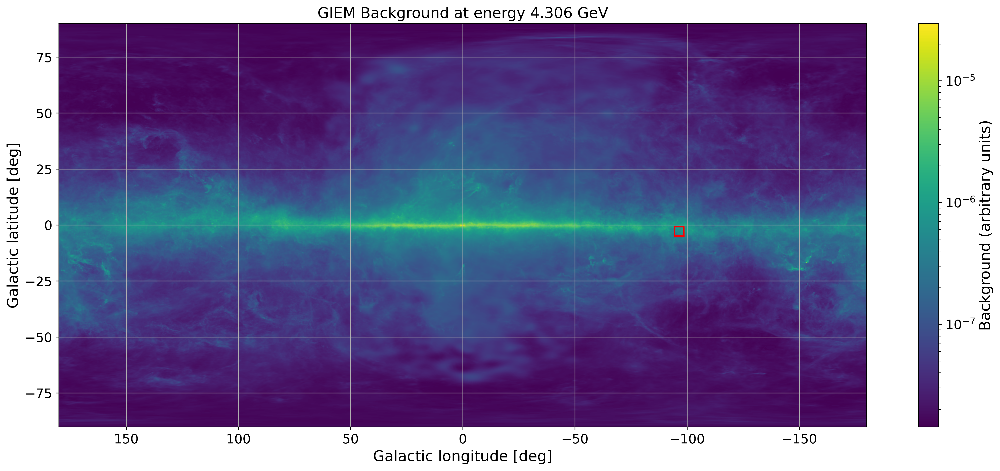

In [151]:
# Test the crop
e_bin = 5

verbose = True
if verbose :
    print(f"Cropped lon edges : {cropped_lon_edges}")
    print(f"TO compare with roi_lon_edges: {roi_lon_edges}")

    print(f"Cropped lat edges : {cropped_lat_edges}")
    print(f"TO compare with roi_lat_edges: {roi_lat_edges}")

fig, ax = plt.subplots(figsize = (20,8))

im = ax.imshow(giem_data[e_bin], origin='lower', extent=[
    np.rad2deg(giem_lon_edges[0]), np.rad2deg(giem_lon_edges[-1]),
    np.rad2deg(giem_lat_edges[0]), np.rad2deg(giem_lat_edges[-1])
], norm=LogNorm())
ax.xaxis.set_inverted(True)
fig.colorbar(im, label="Background (arbitrary units)")
ax.set_title(f"GIEM Background at energy {giem_energies[e_bin]:.3f} GeV")

# Overlay cropped region
ax.plot([np.rad2deg(cropped_lon_edges[0]), np.rad2deg(cropped_lon_edges[-1]), np.rad2deg(cropped_lon_edges[-1]), np.rad2deg(cropped_lon_edges[0]), np.rad2deg(cropped_lon_edges[0])],
         [np.rad2deg(cropped_lat_edges[0]), np.rad2deg(cropped_lat_edges[0]), np.rad2deg(cropped_lat_edges[-1]), np.rad2deg(cropped_lat_edges[-1]), np.rad2deg(cropped_lat_edges[0])],
         color='red')
ax.grid(True)
ax.set_xlabel('Galactic longitude [deg]')
ax.set_ylabel('Galactic latitude [deg]')
fig.savefig(figPath + f"giem_ebin{e_bin}_{target}.eps", format='eps')
plt.show()

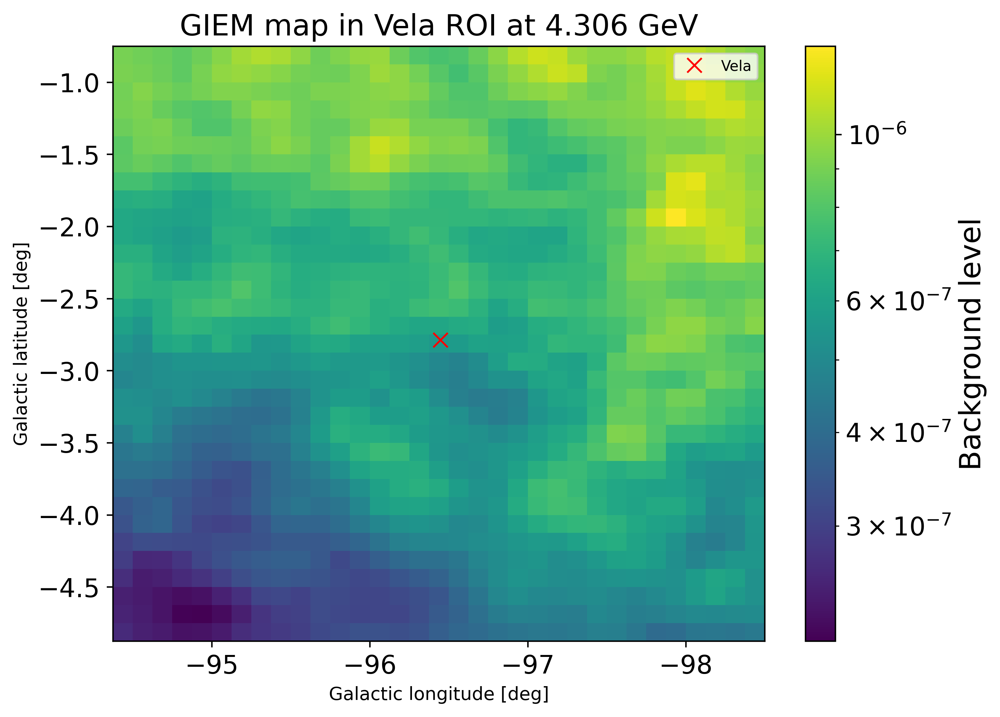

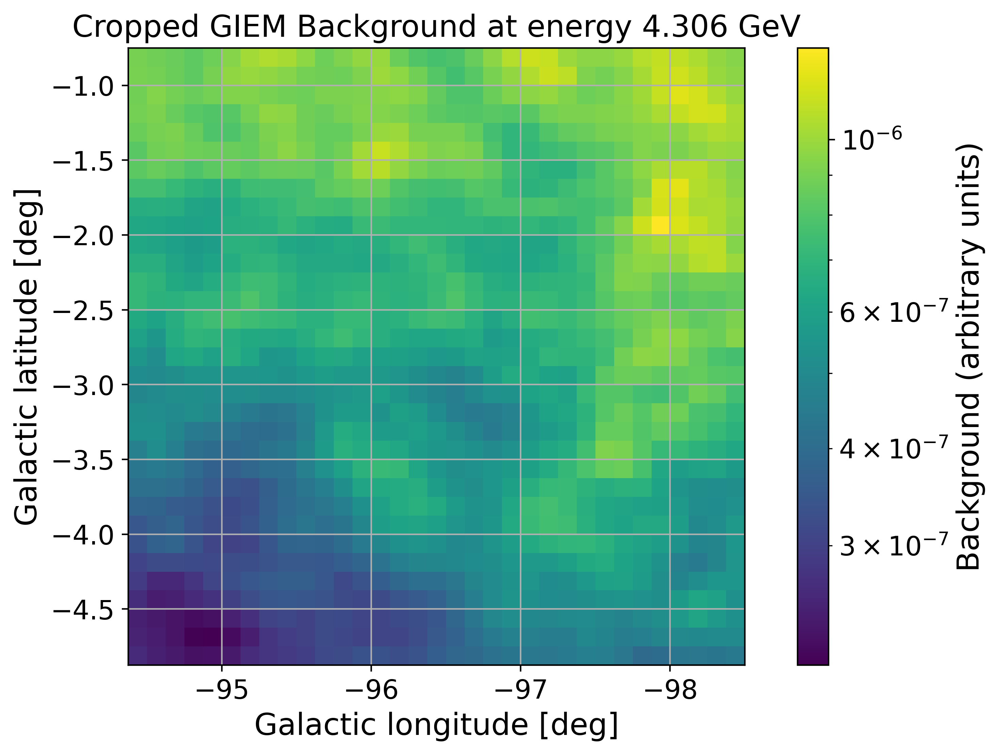

In [152]:
fig, ax = plt.subplots(figsize=(8,6))
im = plot_giem_map(fig, ax, roi_lon_edges, roi_lat_edges, cropped_giem_data[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target)

# To compare with
fig, ax = plt.subplots(figsize=(10, 6))

# Plot cropped data only with its exact extent (in degrees)
im = ax.imshow(
    cropped_giem_data[e_bin],  # cropped data slice only
    origin='lower',
    extent=[
        np.rad2deg(cropped_lon_edges[0]), np.rad2deg(cropped_lon_edges[-1]),
        np.rad2deg(cropped_lat_edges[0]), np.rad2deg(cropped_lat_edges[-1])
    ],
    norm=LogNorm()
)

ax.xaxis.set_inverted(True)  # keep consistent with full plot

fig.colorbar(im, label="Background (arbitrary units)")
ax.set_title(f"Cropped GIEM Background at energy {giem_energies[e_bin]:.3f} GeV")
ax.set_xlabel('Galactic longitude [deg]')
ax.set_ylabel('Galactic latitude [deg]')
ax.grid(True)

plt.show()

<!-- ### Convolve background and source with PSF -->

In [153]:
# def pixel_average_psf(psf_func, i, j, pixel_size_deg, energy, nsample=5):
#     """
#     Approximate the average PSF over pixel (i, j) by sampling on a grid.

#     Parameters
#     ----------
#     psf_func : callable
#         Function PSF(theta, energy).
#     i, j : int
#         Pixel indices relative to center (0,0).
#     pixel_size_deg : float
#         Size of pixel in degrees.
#     energy : float
#         Energy bin.
#     nsample : int
#         Number of samples per pixel side for grid (nsample^2 points total).
#     """
#     # Pixel bounds in degrees
#     y0 = (i - 0.5) * pixel_size_deg
#     y1 = (i + 0.5) * pixel_size_deg
#     x0 = (j - 0.5) * pixel_size_deg
#     x1 = (j + 0.5) * pixel_size_deg

#     # Sample grid inside pixel
#     y = np.linspace(y0, y1, nsample)
#     x = np.linspace(x0, x1, nsample)
#     X, Y = np.meshgrid(x, y)

#     # Compute angular separation theta for all samples
#     theta = np.hypot(X, Y)

#     # Evaluate PSF at all sample points
#     psf_values = psf_func(theta, energy)  # shape (nsample, nsample)

#     # Return mean value over grid
#     return np.mean(psf_values)


def make_psf_kernels(psf_func, shape, pixel_size_deg, energies, nsample=5):
    """
    Create a stack of 2D PSF kernels for all energy bins.

    Parameters
    ----------
    psf_func : callable
        Function PSF(theta, energy) giving PSF at angular separation theta (deg)
        for a given energy (can broadcast over theta and energies).
    shape : tuple
        Shape of the kernel (Ny, Nx).
    pixel_size_deg : float
        Size of one pixel in degrees.
    energies : 1D numpy array
        Energies (n_E,) for which to compute PSF kernels.
    nsample : int
        Number of subsamples per pixel side (nsample^2 samples per pixel).

    Returns
    -------
    psf_kernels : 3D numpy array
        PSF kernels of shape (n_E, Ny, Nx), normalized for convolution.
    valid_mask : 1D numpy array
        Boolean mask indicating which energies produced valid kernels.
    """
    n_E = len(energies)
    Ny, Nx = shape
    PSF_kernels = np.empty((n_E, Ny, Nx), dtype=np.float32)

    # Pixel grid (Ny, Nx) centered at (0,0)
    y = (np.arange(Ny) - Ny // 2) * pixel_size_deg
    x = (np.arange(Nx) - Nx // 2) * pixel_size_deg
    Yc, Xc = np.meshgrid(y, x, indexing='ij')  # shape (Ny, Nx)

    # Sub-pixel sampling grid (nsample, nsample)
    sub_offsets = np.linspace(-0.5, 0.5, nsample, endpoint=False) + 0.5/nsample
    dy, dx = np.meshgrid(sub_offsets, sub_offsets, indexing='ij')  # shape (nsample, nsample)

    # Broadcast subsample offsets to full grid
    # shape: (Ny, Nx, nsample, nsample)
    Y_samples = Yc[..., None, None] + dy * pixel_size_deg
    X_samples = Xc[..., None, None] + dx * pixel_size_deg

    # Angular distance theta at all subsamples
    theta = np.hypot(X_samples, Y_samples)  # shape (Ny, Nx, nsample, nsample)

    for i, energy in enumerate(energies):
        # Evaluate PSF at all subsamples
        psf_vals = psf_func(theta, energy)  # shape (Ny, Nx, nsample, nsample)

        # Average over sub-pixels
        kernel = psf_vals.mean(axis=(-2, -1))  # shape (Ny, Nx)

        PSF_kernels[i, :, :] = kernel

    # Normalize each kernel separately
    kernel_sums = PSF_kernels.sum(axis=(1, 2), keepdims=True)  # shape (n_E,1,1)

    valid_mask = (kernel_sums.squeeze() > 0)  # shape (n_E,)
    kernel_sums[kernel_sums == 0] = 1  # avoid divide-by-zero

    PSF_kernels /= kernel_sums

    return PSF_kernels, valid_mask

In [154]:
pixel_size = np.rad2deg(np.abs(giem_lon_edges[-1] - giem_lon_edges[0])/(len(giem_lon_edges)-1))
shape = cropped_giem_data[0].shape

verbose = True
if verbose:
    print(f"Computed shape of ROI : {shape}")
    print(f"Computed pixel size : {pixel_size} deg")

PSF_kernels, valid_mask_psf = make_psf_kernels(PSF_bar, shape, pixel_size, giem_energies, nsample=10)

Computed shape of ROI : (33, 33)
Computed pixel size : 0.125 deg


In [155]:
def plot_kernel(fig, ax, roi_lon_edges, roi_lat_edges, kernel, energy, target_lon, target_lat, target_name):
    im = plot_map(fig, ax, roi_lon_edges, roi_lat_edges, kernel, energy, target_lon, target_lat, target_name, norm=LogNorm())
    ax.set_title(f"Exposure-weighted PSF kernel at {energy:.3f} GeV")
    fig.colorbar(im)

Max index : 544
value : 0.12235789746046066
Sum value : 0.9999998807907104


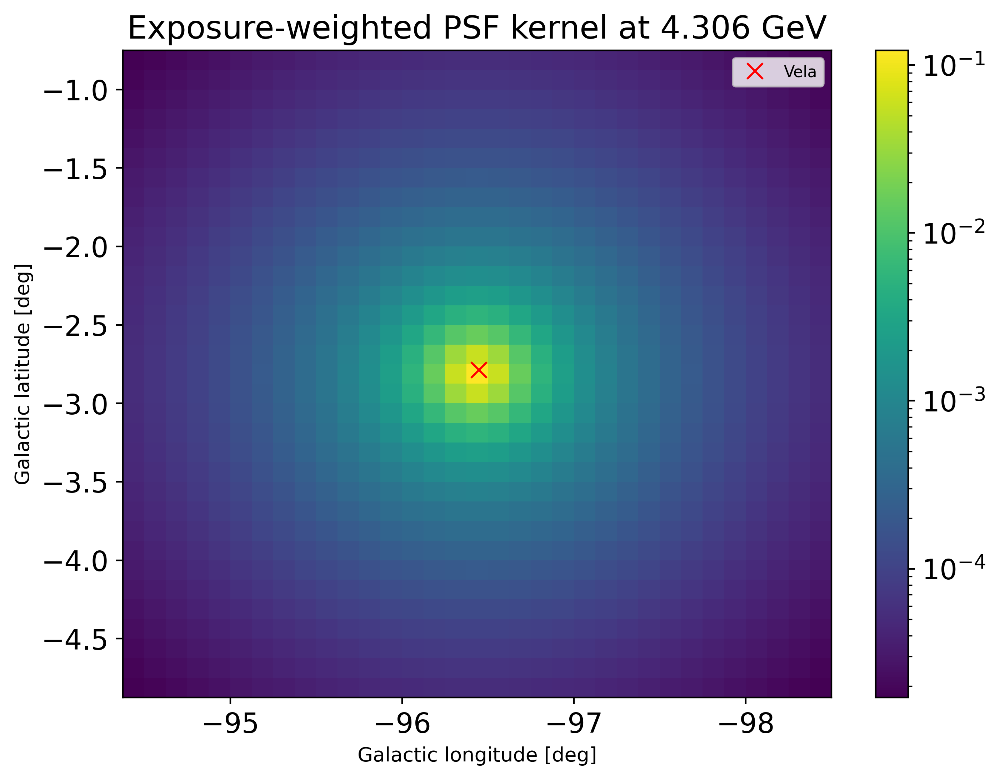

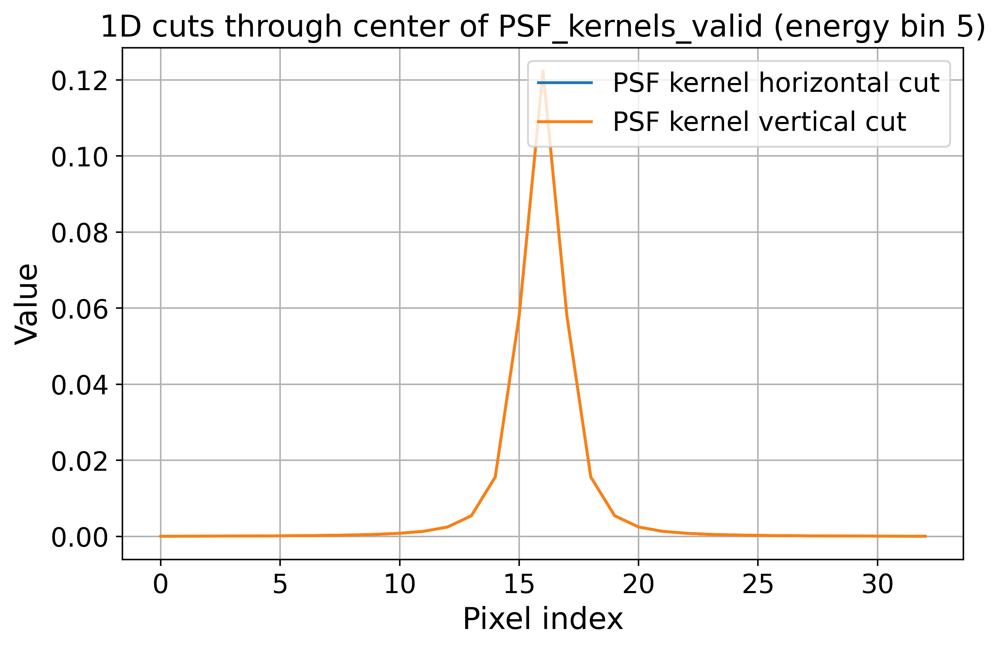

In [156]:
# Plot PSF kernel
fig, ax = plt.subplots(figsize=(8,6))
im = plot_kernel(fig, ax, roi_lon_edges, roi_lat_edges, PSF_kernels[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target)

# DEBUG
max_idx = np.argmax(PSF_kernels[e_bin])
print(f"Max index : {max_idx}")
print(f"value : {np.max(PSF_kernels[e_bin])}") 
print(f"Sum value : {np.sum(PSF_kernels[e_bin])}") 

fig.savefig(figPath + "Pbar_kernel.eps", format='eps')

# Plot the same 1D cut for PSF_kernels_valid[e_bin]
center_y, center_x = np.array(PSF_kernels[e_bin].shape) // 2

psf_cut_x = PSF_kernels[e_bin][center_y, :]  # horizontal cut
psf_cut_y = PSF_kernels[e_bin][:, center_x]  # vertical cut

plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(psf_cut_x)), psf_cut_x, label='PSF kernel horizontal cut')
plt.plot(np.arange(len(psf_cut_y)), psf_cut_y, label='PSF kernel vertical cut')
plt.xlabel('Pixel index')
plt.ylabel('Value')
plt.title(f'1D cuts through center of PSF_kernels_valid (energy bin {e_bin})')
plt.legend()
plt.grid(True)
plt.show()

<!-- ### Create mask for valid energy bins -->

In [157]:
counts_threshold = 25

# Measurement valid mask: True if df has at least 10 rows
valid_mask_meas = np.array([len(df_bin) >= counts_threshold for df_bin in dfs])

# Combine masks
valid_mask = valid_mask_psf & valid_mask_meas
valid_mask_edges = np.zeros(len(ENERGY_BINS_EDGES), dtype=bool)

# For each edge (except first and last), mark True if either adjacent bin is valid
valid_mask_edges[1:-1] = valid_mask[:-1] | valid_mask[1:]

# Optionally, handle first and last edges separately:
valid_mask_edges[0] = valid_mask[0]         # first edge corresponds to first bin start
valid_mask_edges[-1] = valid_mask[-1]       # last edge corresponds to last bin end

E_bin_centers_valid = E_bin_centers[valid_mask]
E_bin_edges_valid = ENERGY_BINS_EDGES[valid_mask_edges]
cropped_giem_data_valid = cropped_giem_data[valid_mask,:,:]
PSF_kernels_valid = PSF_kernels[valid_mask,:,:]

# Transpose exposure maps (E, Nx, Ny) -> (E, Ny, Nx)
exposure_maps_valid = np.array([exposure_maps[ene].T for ene in sorted(E_bin_centers_valid) if ene in exposure_maps])
print(f"DEBUG : exposure maps valid shape : {exposure_maps_valid.shape}")

# Use np.array(dfs) to allow boolean indexing with valid_mask
dfs_valid = np.array(dfs, dtype=object)[valid_mask]

verbose = True
if verbose:
    print(f"Number of valid energies : {len(E_bin_centers_valid)}")
    print(f"DEBUG : valid energies : {E_bin_centers_valid}")
    print(f"DEBUG : valid energies edges : {E_bin_edges_valid}")
    print(f"DEBUG : cropped_giem_data shape : {cropped_giem_data_valid.shape}")
    print(f"DEBUG : PSF_kernels_valid shape : {PSF_kernels_valid.shape}")
    print(f"DEBUG : dfs_valid shape : {dfs_valid.shape}")
    print(f"DEBUG : dfs_valid type : {dfs_valid.dtype}")


DEBUG : exposure maps valid shape : (8, 33, 33)
Number of valid energies : 8
DEBUG : valid energies : [ 1.509  1.961  2.549  3.313  4.597  7.273 12.285 20.75 ]
DEBUG : valid energies edges : [ 1.32381626  1.72050654  2.23606768  2.90612012  3.7769582   5.59609532
  9.45240534 15.96612667 26.96850072]
DEBUG : cropped_giem_data shape : (8, 33, 33)
DEBUG : PSF_kernels_valid shape : (8, 33, 33)
DEBUG : dfs_valid shape : (8,)
DEBUG : dfs_valid type : object


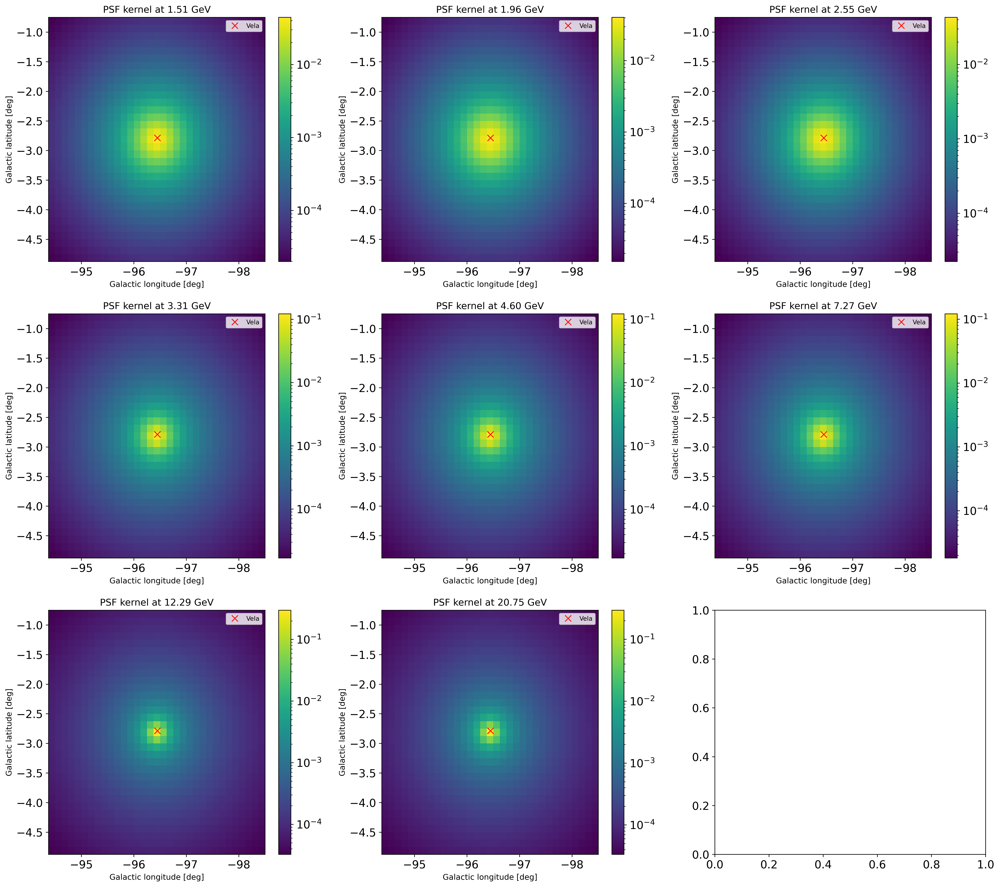

In [158]:
fig, axs = plt.subplots(3, 3, figsize=(18, 16))
axs = axs.flatten()

for idx in range(len(E_bin_centers_valid)):
    ax = axs[idx]
    energy = E_bin_centers_valid[idx]
    kernel = PSF_kernels_valid[idx].T  # transpose for correct orientation
    plot_kernel(fig, ax, roi_lon_edges, roi_lat_edges, kernel, energy, target_lon, target_lat, target)
    ax.set_title(f"PSF kernel at {energy:.2f} GeV", fontsize=12)

plt.tight_layout()
plt.show()

<!-- ### Convolve background -->

In [159]:
from astropy.convolution import convolve

# point_source_convolved[i] = convolve(src, psf, mode='constant', cval=0.0)

# Assuming:
# - cropped_giem_data.shape = (n_E, Ny, Nx)
# - PSF_kernels.shape = (n_E, Ny, Nx)

GIEM_convolved = np.empty_like(cropped_giem_data_valid)

for i, (bkg, psf, expo) in enumerate(zip(cropped_giem_data_valid, PSF_kernels_valid, exposure_maps_valid)):
    # Convolve the 2D background map with the corresponding PSF kernel
    convolved = convolve(bkg * expo, psf)
    GIEM_convolved[i] = convolved

verbose = True 
if verbose :
    print(f"convolved_GIEM shape : {GIEM_convolved.shape}")

convolved_GIEM shape : (8, 33, 33)


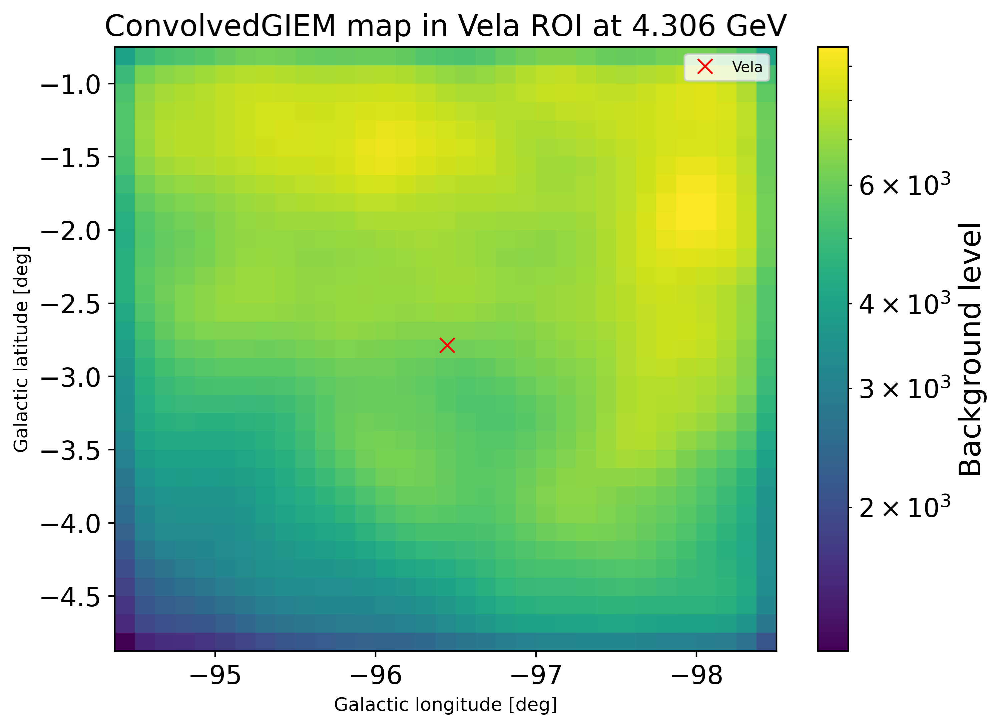

In [160]:
fig, ax = plt.subplots(figsize=(8,6))
im = plot_giem_map(fig, ax, roi_lon_edges, roi_lat_edges, GIEM_convolved[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target, convolved=True)

<!-- ### Point source maps -->

In [161]:
point_source_maps = np.zeros_like(cropped_giem_data_valid)

# Convert (lon, lat) to pixel indices
lon_min, lon_max = roi_lon_edges[0], roi_lon_edges[-1]
lat_min, lat_max = roi_lat_edges[0], roi_lat_edges[-1]

# Grid resolution
n_lat, n_lon = cropped_giem_data_valid.shape[1:]  # Ny, Nx

target_lon_conv = conv_lon_deg(target_lon)

# Assume roi_lon_edges and roi_lat_edges are 1D arrays of bin edges (len = Nx+1, Ny+1)
pixel_x = np.digitize(target_lon_conv, np.rad2deg(roi_lon_edges)) - 1  # subtract 1 for zero-based indexing
pixel_y = np.digitize(target_lat, np.rad2deg(roi_lat_edges)) - 1

# Clip indices to stay within map bounds
pixel_x = np.clip(pixel_x, 0, len(roi_lon_edges) - 2)
pixel_y = np.clip(pixel_y, 0, len(roi_lat_edges) - 2)

# Place delta in all energy bins (or scale later with energy dependence)
for i in range(len(E_bin_centers_valid)):
    point_source_maps[i, pixel_y, pixel_x] = 1.0  # Dirac delta

point_source_convolved = np.empty_like(point_source_maps)

for i, (src, psf, expo) in enumerate(zip(point_source_maps, PSF_kernels_valid, exposure_maps_valid)):
    point_source_convolved[i] = convolve(src * expo, psf,
    normalize_kernel=False,
    boundary='wrap' 
    )

verbose = True 
if verbose :
    print(f"point_source_convolved shape : {point_source_convolved.shape}")

point_source_convolved shape : (8, 33, 33)


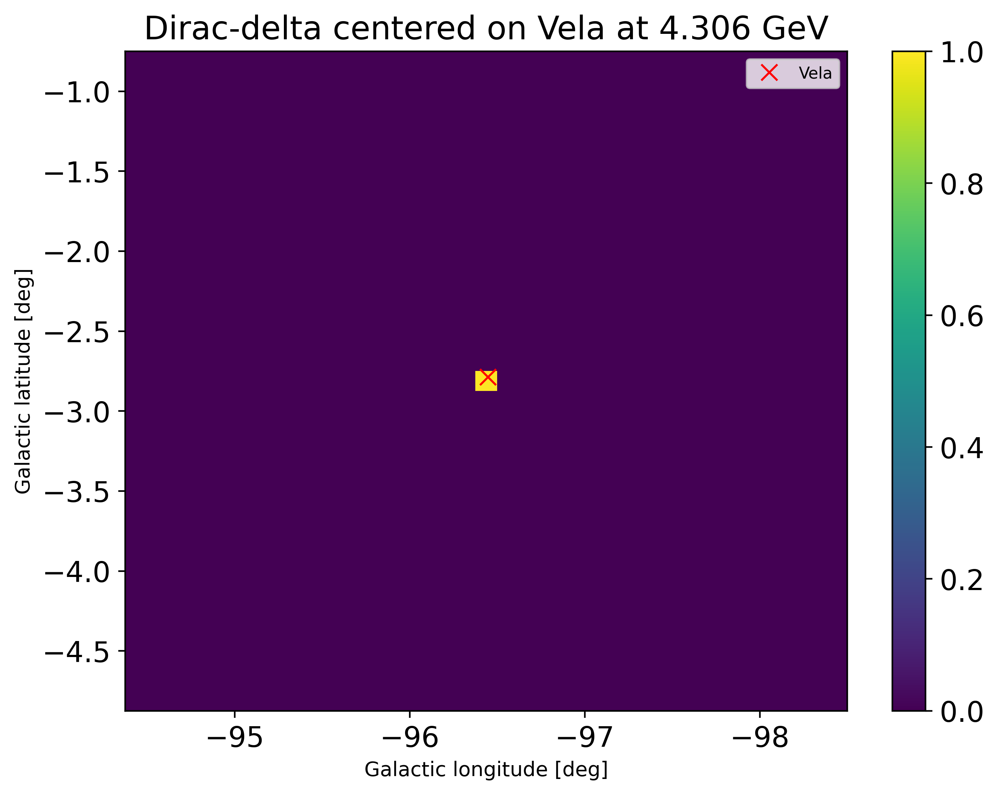

In [162]:
# Test dirac deltas

def plot_dirac(fig, ax, roi_lon_edges, roi_lat_edges, dirac_map, energy, target_lon, target_lat, target_name, convolved = False):
    title = f"Dirac-delta centered on {target_name} at {energy:.3f} GeV"
    norm = None
    if convolved:
        title = "Convolved " + title
        norm = LogNorm()
    im = plot_map(fig, ax, roi_lon_edges, roi_lat_edges, dirac_map, energy, target_lon, target_lat, target_name, norm=norm)
    
    ax.set_title(title)
    fig.colorbar(im)

fig, ax = plt.subplots(figsize=(8,6))
plot_dirac(fig, ax, roi_lon_edges, roi_lat_edges, point_source_maps[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target)

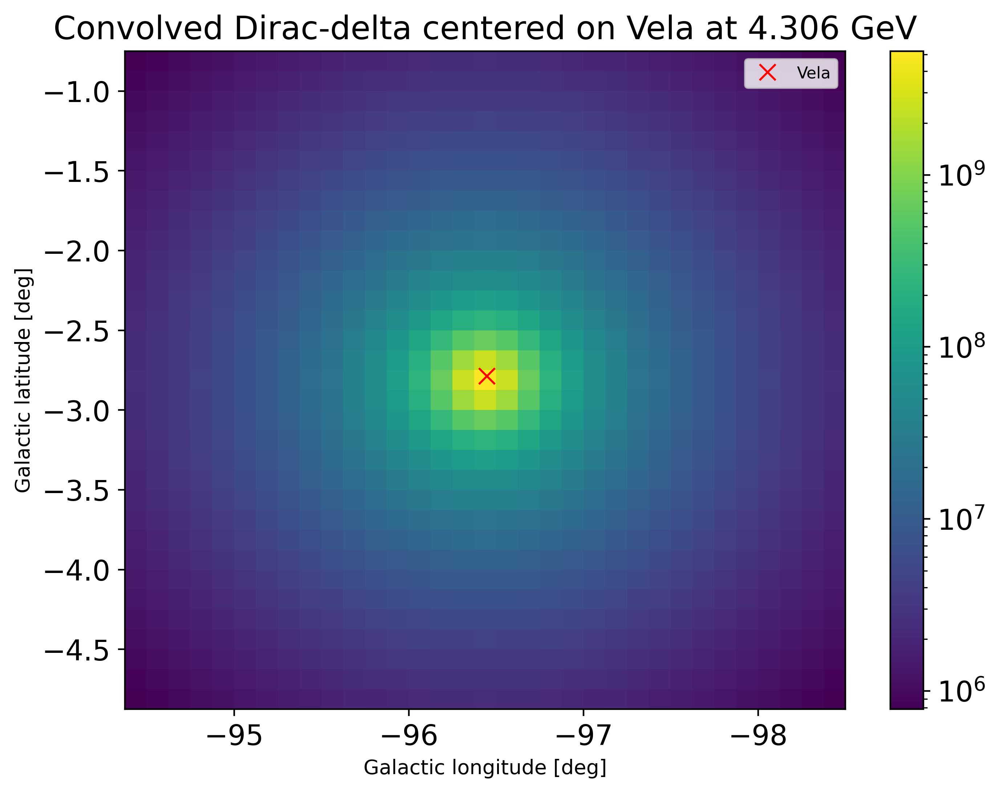

In [163]:
# Test dirac deltas
fig, ax = plt.subplots(figsize=(8,6))
plot_dirac(fig, ax, roi_lon_edges, roi_lat_edges, point_source_convolved[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target, convolved = True)
fig.savefig(figPath + f"diracConvolved_e={e_bin}.png")

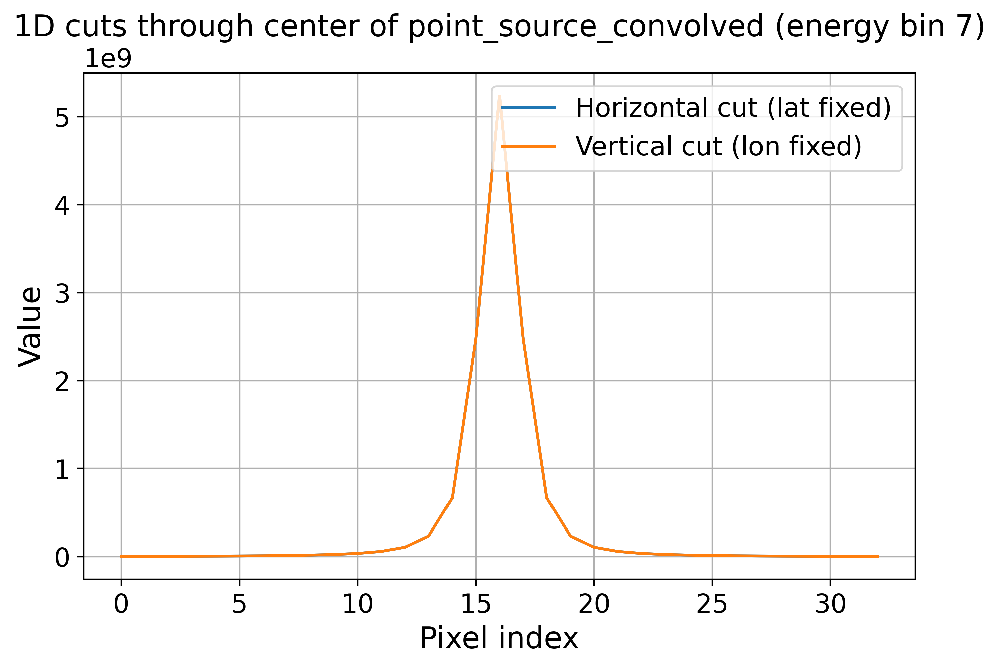

In [164]:
# Plot a 1D cut through the center of point_source_convolved at energy bin i

center_y, center_x = np.array(point_source_convolved[e_bin].shape) // 2

cut_x = point_source_convolved[e_bin][center_y, :]  # horizontal cut (latitude fixed)
cut_y = point_source_convolved[e_bin][:, center_x]  # vertical cut (longitude fixed)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(cut_x)), cut_x, label='Horizontal cut (lat fixed)')
plt.plot(np.arange(len(cut_y)), cut_y, label='Vertical cut (lon fixed)')
plt.xlabel('Pixel index')
plt.ylabel('Value')
plt.title(f'1D cuts through center of point_source_convolved (energy bin {i})')
plt.legend()
plt.grid(True)
plt.show()

In [165]:
print(f"DEBUG : sum is {np.sum(point_source_convolved[e_bin])}")

DEBUG : sum is 43020479585.047714


<!-- ### Isotropic background -->

### Load isotropic BG

In [166]:
isotropic_value_per_energy = np.ones(len(E_bin_centers_valid))  # or apply energy scaling later

isotropic_maps = np.ones_like(cropped_giem_data_valid)

for i in range(len(E_bin_centers_valid)):
    isotropic_maps[i] *= isotropic_value_per_energy[i]

verbose = True 
if verbose :
    print(f"isotropic maps shape : {isotropic_maps.shape}")

isotropic maps shape : (8, 33, 33)


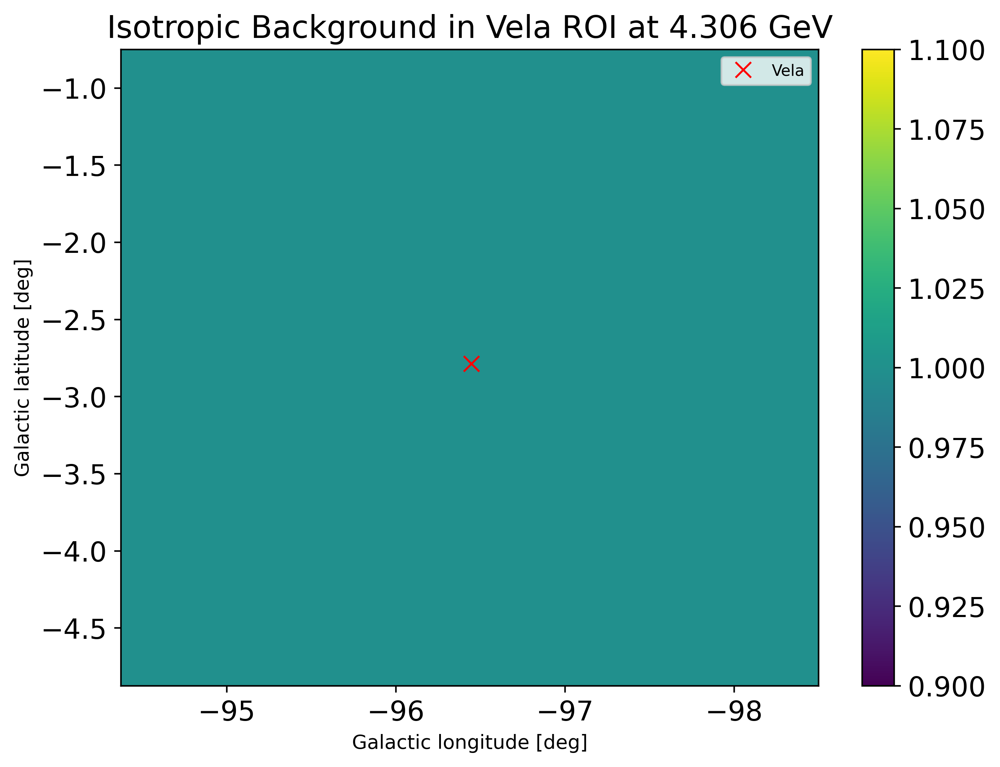

In [167]:
def plot_iso(fig, ax, roi_lon_edges, roi_lat_edges, iso_map, energy, target_lon, target_lat, target_name, convolved = False):
    title = f"Isotropic Background in {target_name} ROI at {energy:.3f} GeV"
    norm = None
    if convolved:
        title = "Convolved " + title
    im = plot_map(fig, ax, roi_lon_edges, roi_lat_edges, iso_map, energy, target_lon, target_lat, target_name, norm=norm)
    
    ax.set_title(title)
    fig.colorbar(im)

fig, ax = plt.subplots(figsize=(8,6))
plot_iso(fig, ax, roi_lon_edges, roi_lat_edges, isotropic_maps[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target, convolved = False)


In [168]:
isotropic_convolved = isotropic_maps.copy()
for i, (iso, psf, expo) in enumerate(zip(isotropic_maps, PSF_kernels_valid, exposure_maps_valid)):
    isotropic_convolved[i] = convolve(iso * expo, psf)

verbose = True 
if verbose :
    print(f"isotropic convolved shape : {isotropic_convolved.shape}")

isotropic convolved shape : (8, 33, 33)


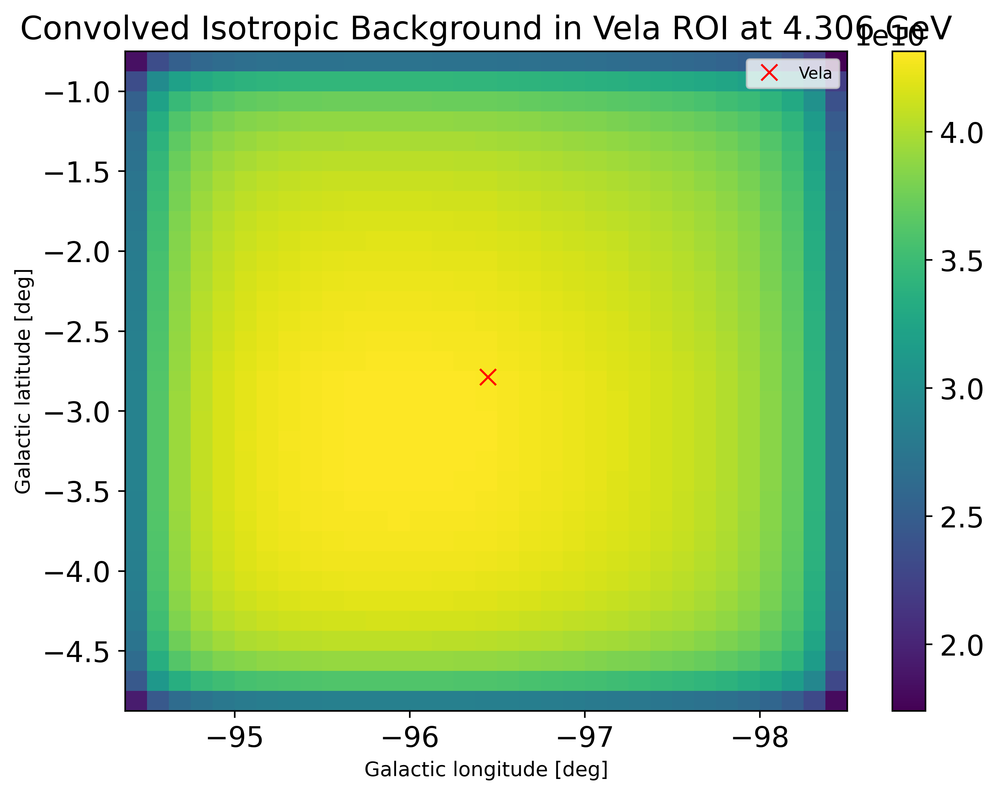

In [169]:
fig, ax = plt.subplots(figsize=(8,6))
plot_iso(fig, ax, roi_lon_edges, roi_lat_edges, isotropic_convolved[e_bin].T, giem_energies[e_bin], target_lon, target_lat, target, convolved = True)

DEBUG : selected energy : 7.273


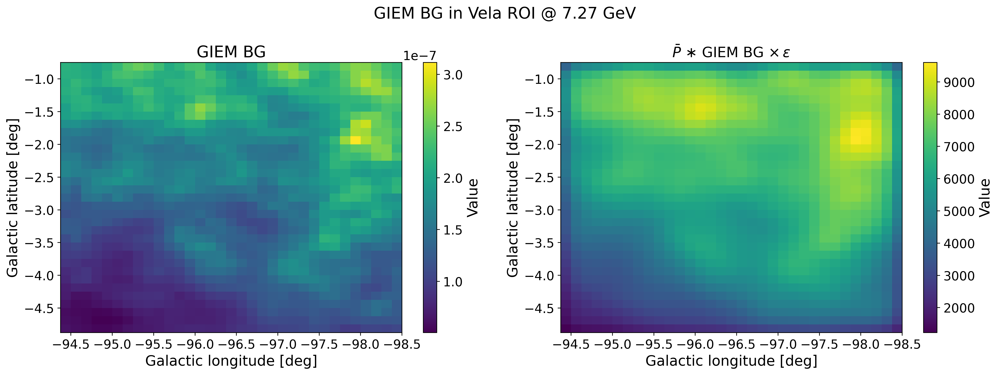

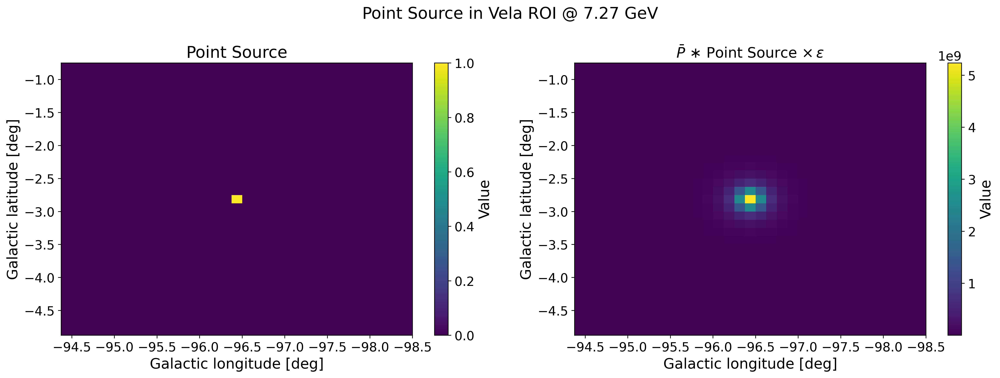

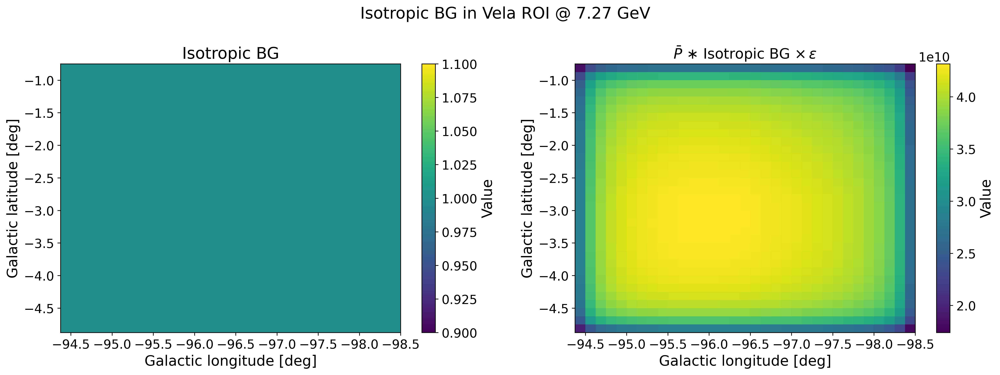

In [170]:
# Select energy bin index 
i = e_bin  # adjust as needed for your energy bin of interest
ene = E_bin_centers_valid[i]
print(f"DEBUG : selected energy : {ene}")

# Get the exposure map for the selected energy
exposure_map = exposure_maps[ene]

# Font settings
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 20
})

# Prepare the three sets of maps: (original, exposure-weighted)
maps_to_plot = [
    (cropped_giem_data_valid[i], GIEM_convolved[i], "GIEM BG"),
    (point_source_maps[i], point_source_convolved[i], "Point Source"),
    (isotropic_maps[i], isotropic_convolved[i], "Isotropic BG"),
]

# Create 3 separate figures, each with 1 row and 2 columns
for idx, (orig, convolved, title) in enumerate(maps_to_plot):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left : original
    im0 = axs[0].imshow(
        orig, origin='lower',
        extent=[
            np.rad2deg(roi_lon_edges[0]), np.rad2deg(roi_lon_edges[-1]),
            np.rad2deg(roi_lat_edges[0]), np.rad2deg(roi_lat_edges[-1])
        ],
        aspect='auto'
    )
    axs[0].set_title(f"{title}", fontsize=18)
    axs[0].set_xlabel('Galactic longitude [deg]', fontsize=16)
    axs[0].set_ylabel('Galactic latitude [deg]', fontsize=16)
    axs[0].xaxis.set_inverted(True)
    cbar0 = fig.colorbar(im0, ax=axs[0], orientation='vertical')
    cbar0.ax.tick_params(labelsize=14)
    cbar0.set_label('Value', fontsize=16)

    # Center: convolved
    im1 = axs[1].imshow(
        convolved, origin='lower',
        extent=[
            np.rad2deg(roi_lon_edges[0]), np.rad2deg(roi_lon_edges[-1]),
            np.rad2deg(roi_lat_edges[0]), np.rad2deg(roi_lat_edges[-1])
        ],
        aspect='auto'
    )
    axs[1].set_title(f"$\\bar{{P}}$ $\\ast$ {title} $\\times \, \\varepsilon$ ", fontsize=16)
    axs[1].set_xlabel('Galactic longitude [deg]', fontsize=16)
    axs[1].set_ylabel('Galactic latitude [deg]', fontsize=16)
    axs[1].xaxis.set_inverted(True)
    cbar1 = fig.colorbar(im1, ax=axs[1], orientation='vertical')
    cbar1.ax.tick_params(labelsize=14)
    cbar1.set_label('Value', fontsize=16)

    fig.suptitle(f"{title} in {target} ROI @ {ene:.2f} GeV", fontsize=18)
    fig.savefig(figPath + f"{title.replace(' ', '_')}_{target}.png")
    fig.savefig(figPath + f"{title.replace(' ', '_')}_{target}.eps", format="eps")

    plt.tight_layout()
    plt.show()

<!-- ### Format data -->

In [171]:
def build_counts_cube(dfs_valid, lon_edges, lat_edges):
    """
    Converts list of DataFrames (dfs_valid) into a 3D data cube of counts.

    Args:
        dfs_valid (list of pd.DataFrame): One DataFrame per energy bin, with 'lon', 'lat' columns.
        lon_edges (array): Longitude bin edges in degrees.
        lat_edges (array): Latitude bin edges in degrees.

    Returns:
        np.ndarray: Counts cube of shape (N_energy, N_lat, N_lon)
    """
    N_energy = len(dfs_valid)
    N_lon = len(lon_edges) - 1
    N_lat = len(lat_edges) - 1

    counts_cube = np.zeros((N_energy, N_lat, N_lon), dtype=np.float32)

    for i, df in enumerate(dfs_valid):
        hist2d, _, _ = np.histogram2d(
            df['lat'], df['lon'],  # Note: lat first for y-axis
            bins=[lat_edges, lon_edges]
        )
        counts_cube[i] = hist2d  # Shape (N_lat, N_lon)

    return counts_cube

In [172]:
flight_data_cube = build_counts_cube(dfs_valid, roi_lon_edges, roi_lat_edges)
print(f"DEBUG : flight_data_cube shape : {flight_data_cube.shape}")

DEBUG : flight_data_cube shape : (8, 33, 33)


<!-- ### Define model function -->

In [173]:
def model_counts_PL(params, 
                 galactic_maps, isotropic_maps, point_source_maps, 
                 exposure_maps, energies, E_ref=1.0):
    """
    Build model predicted counts cube.

    Args:
        params: [A_gal, A_iso, gamma_iso, A_src, gamma_src]
        galactic_maps: shape (n_E, ny, nx)
        isotropic_maps: shape (n_E, ny, nx)
        point_source_maps: shape (n_E, ny, nx)
        exposure_maps: shape (n_E, ny, nx)
        energies: array of energy bin centers (GeV)
        E_ref: reference energy for power-law scaling (GeV)
    Returns:
        model_counts: predicted counts cube (n_E, ny, nx)
    """
    logA_gal, logA_iso, gamma_iso, logA_src, gamma_src = params
    A_gal = 10**logA_gal
    A_iso = 10**logA_iso
    A_src = 10**logA_src
    
    E_ratio_src = (energies / E_ref)**(-gamma_src)
    E_ratio_iso = (energies / E_ref)**(-gamma_iso)

    model_gal = A_gal * galactic_maps #* exposure_maps
    model_iso = A_iso * isotropic_maps * E_ratio_iso[:, None, None] #* exposure_maps
    model_src = A_src * point_source_maps * E_ratio_src[:, None, None] #* exposure_maps

    # Total model is sum of components
    model = model_gal + model_iso + model_src 

    return model, model_gal, model_iso, model_src

def model_counts_parabolae(params, 
                           galactic_maps, isotropic_maps, point_source_maps, 
                           exposure_maps, energies, E_ref=1.0):
    """
    Build model predicted counts cube with log-parabola spectra.

    Args:
        params: [logA_gal, logA_iso, gamma_iso, logA_src, gamma_src, beta_src]
        galactic_maps: shape (n_E, ny, nx)
        isotropic_maps: shape (n_E, ny, nx)
        point_source_maps: shape (n_E, ny, nx)
        exposure_maps: shape (n_E, ny, nx)
        energies: array of energy bin centers (GeV)
        E_ref: reference energy for normalization (GeV)

    Returns:
        model_counts: predicted counts cube (n_E, ny, nx)
    """
    # Unpack parameters
    logA_gal, logA_iso, logA_src, gamma_src, beta_src = params

    # Convert log10 amplitudes to linear scale
    A_gal = 10**logA_gal
    A_iso = 10**logA_iso
    A_src = 10**logA_src

    # log-parabola energy scaling
    log_E_ratio = np.log(energies / E_ref)
    S_src = A_src * (energies / E_ref)**(-gamma_src) * np.exp(-beta_src * log_E_ratio**2)

    model_gal = A_gal * galactic_maps #* exposure_maps
    model_iso = A_iso * isotropic_maps #* exposure_maps
    model_src = A_src * point_source_maps * S_src[:, None, None] #* exposure_maps

    # Combine spatial templates with spectral shapes
    model = model_gal + model_iso + model_src

    return model, model_gal, model_iso, model_src



<!-- ### Define log likelihood -->

In [174]:
def log_likelihood(model_counts, data_counts):
    """
    Poisson log-likelihood.

    Args:
        model_counts: array of predicted counts (same shape as data)
        data_counts: array of observed counts

    Returns:
        log-likelihood (float)
    """
    # Small epsilon to avoid log(0)
    epsilon = 1e-10
    mu = model_counts + epsilon
    Ni = data_counts

    ll = -mu + Ni * np.log(mu)
    return np.sum(ll)

def neg_log_likelihood_PL(logA_gal, logA_iso, gamma_iso, logA_src, gamma_src):
    """To minimize"""

    E_ref = 1
    params = (logA_gal, logA_iso,  gamma_iso, logA_src, gamma_src) # in tuple

    modelCounts, _, _, _ = model_counts_PL(params,
                 GIEM_convolved, isotropic_convolved, point_source_convolved, 
                 exposure_maps_valid, E_bin_centers_valid, E_ref) 

    return -log_likelihood(modelCounts, flight_data_cube)

def neg_log_likelihood_parabolae(logA_gal, logA_iso, logA_src, gamma_src, beta_src):
    """To minimize"""

    E_ref = 1
    params = (logA_gal, logA_iso, logA_src, gamma_src, beta_src) # in tuple

    modelCounts,_,_,_ = model_counts_parabolae(params,
                 GIEM_convolved, isotropic_convolved, point_source_convolved, 
                 exposure_maps_valid, E_bin_centers_valid, E_ref) 

    return -log_likelihood(modelCounts, flight_data_cube)

<!-- ### Fit the model to data -->

In [175]:
import iminuit
import numpy as np

# List of models to fit
model_types = ["PL", "parabolae"]

# Store fit results
fit_results = {}

for model_type in model_types:
    print(f"\n=== Fitting model: {model_type} ===")

    if model_type == "PL":
        neg_log_likelihood = neg_log_likelihood_PL
        init_params = dict(
            logA_gal=-7,
            logA_iso=-11,
            gamma_iso=3,
            logA_src=-7,
            gamma_src=2.3
        )
        limits = [
            (-20, -2),  # logA_gal
            (-20, 0),  # logA_iso
            (1, 5.0),  # gamma_iso
            (-20, -2),  # logA_src
            (1, 5.0)  # gamma_src
        ]
        errors = [0.05, 0.05, 0.01, 0.05, 0.01]
    
    elif model_type == "parabolae":
        neg_log_likelihood = neg_log_likelihood_parabolae
        init_params = dict(
            logA_gal=-7,
            logA_iso=-11,
            logA_src=-7,
            gamma_src=2.3,
            beta_src=0.0
        )
        limits = [
            (-20, -2),  # logA_gal
            (-20, 0),  # logA_iso
            (-20, -2),  # logA_src
            (1, 5.0), # gamma_src
            (-1.0, 1.0) # beta_src
        ]
        errors = [0.1, 0.1, 0.1, 0.1, 0.05]

    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    # Initialize Minuit
    m = iminuit.Minuit(neg_log_likelihood, **init_params)
    m.limits = limits
    m.errors = errors

    # Minimize
    m.migrad()
    m.hesse()

    # Save results
    fit_results[model_type] = {
        "minuit": m,
        "nll": m.fval,
        "ndof": np.prod(flight_data_cube.shape) - len(m.parameters),  # degrees of freedom
        "n_params": len(m.parameters)
    }

    # Print results
    print("Best-fit parameters:")
    for name in m.parameters:
        print(f"  {name} = {m.values[name]:.5f} ± {m.errors[name]:.5f}")
    print(f"Negative Log-Likelihood: {m.fval:.2f}")

# === Compare models ===
nll_PL = fit_results["PL"]["nll"]
nll_parabolae = fit_results["parabolae"]["nll"]
k_PL = fit_results["PL"]["n_params"]
k_parabolae = fit_results["parabolae"]["n_params"]
n_data = np.prod(flight_data_cube.shape)  # total number of bins

# Likelihood ratio test (only valid if nested models)
delta_nll = nll_PL - nll_parabolae
delta_k = k_parabolae - k_PL
print("\n=== Model Comparison ===")
print(f"ΔNLL = {delta_nll:.2f} (parabolae better if ΔNLL > 0)")

# AIC and BIC
AIC_PL = 2 * k_PL + 2 * nll_PL
AIC_parabolae = 2 * k_parabolae + 2 * nll_parabolae
BIC_PL = k_PL * np.log(n_data) + 2 * nll_PL
BIC_parabolae = k_parabolae * np.log(n_data) + 2 * nll_parabolae

print(f"AIC: PL = {AIC_PL:.2f}, parabolae = {AIC_parabolae:.2f}")
print(f"BIC: PL = {BIC_PL:.2f}, parabolae = {BIC_parabolae:.2f}")

if AIC_parabolae < AIC_PL:
    print("AIC prefers: parabolae")
else:
    print("AIC prefers: PL")

if BIC_parabolae < BIC_PL:
    print("BIC prefers: parabolae")
else:
    print("BIC prefers: PL")



=== Fitting model: PL ===


Best-fit parameters:
  logA_gal = -5.43941 ± 0.09775
  logA_iso = -10.83022 ± 0.08556
  gamma_iso = 1.00008 ± 3.46381
  logA_src = -6.44884 ± 0.02330
  gamma_src = 1.42853 ± 0.03444
Negative Log-Likelihood: -4745.92

=== Fitting model: parabolae ===
Best-fit parameters:
  logA_gal = -5.21547 ± 0.04363
  logA_iso = -12.07704 ± 0.12044
  logA_src = -3.29062 ± 0.00666
  gamma_src = 1.00000 ± 0.01349
  beta_src = 0.12940 ± 0.01009
Negative Log-Likelihood: -4765.04

=== Model Comparison ===
ΔNLL = 19.11 (parabolae better if ΔNLL > 0)
AIC: PL = -9481.85, parabolae = -9520.08
BIC: PL = -9446.48, parabolae = -9484.71
AIC prefers: parabolae
BIC prefers: parabolae


In [176]:
test_params = [-5.0, -10.0, 3,  -7.0, 2.0]
model, model_gal, model_iso, model_src = model_counts_PL(
    test_params,
    GIEM_convolved,
    isotropic_convolved,
    point_source_convolved,
    exposure_maps_valid,
    E_bin_centers_valid
)
print(f"Predicted counts sum: {np.sum(model):e}")
print(f"Data counts sum: {np.sum(flight_data_cube):e}")

Predicted counts sum: 2.219186e+03
Data counts sum: 7.487000e+03


<!-- ### Verify the fit -->

In [177]:
# --- Compute models for both PL and parabolae ---
# Store best-fit parameters and models for both
results = {}

for model_type in ["PL", "parabolae"]:
    m  = fit_results[model_type]['minuit']
    if model_type == "PL":
        
        best_params = [
            m.values['logA_gal'],
            m.values['logA_iso'],
            m.values['gamma_iso'],
            m.values['logA_src'],
            m.values['gamma_src']
        ]
        model, model_gal, model_iso, model_src = model_counts_PL(
            best_params,
            GIEM_convolved,
            isotropic_convolved,
            point_source_convolved,
            exposure_maps_valid,
            E_bin_centers_valid
        )
        neg_log_likelihood = neg_log_likelihood_PL
    elif model_type == "parabolae":
        best_params = [
            m.values['logA_gal'],
            m.values['logA_iso'],
            m.values['logA_src'],
            m.values['gamma_src'],
            m.values['beta_src'],
        ]
        model, model_gal, model_iso, model_src = model_counts_parabolae(
            best_params,
            GIEM_convolved,
            isotropic_convolved,
            point_source_convolved,
            exposure_maps_valid,
            E_bin_centers_valid
        )
        neg_log_likelihood = neg_log_likelihood_parabolae
    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    results[model_type] = {
        "params": best_params,
        "model": model,
        "model_gal" : model_gal,
        "model_iso" : model_iso,
        "model_src" : model_src,
    }

    print(f"\n--- {model_type} Fit Summary ---")
    print(f"Predicted counts sum: {np.sum(model):e}")
    print(f"Data counts sum: {np.sum(flight_data_cube):e}")

    # Define and evaluate loss function
    def loss(args):
        return 1 / neg_log_likelihood(*args)

    L = loss(best_params)
    print(f"Loss (1/Likelihood): {L:.6e}")


--- PL Fit Summary ---
Predicted counts sum: 7.487584e+03
Data counts sum: 7.487000e+03
Loss (1/Likelihood): -2.107072e-04

--- parabolae Fit Summary ---
Predicted counts sum: 7.486929e+03
Data counts sum: 7.487000e+03
Loss (1/Likelihood): -2.098619e-04


DEBUG : flight data allE shape : (33, 33)
DEBUG : model PL allE shape : (33, 33)
DEBUG : model parabolae allE shape : (33, 33)


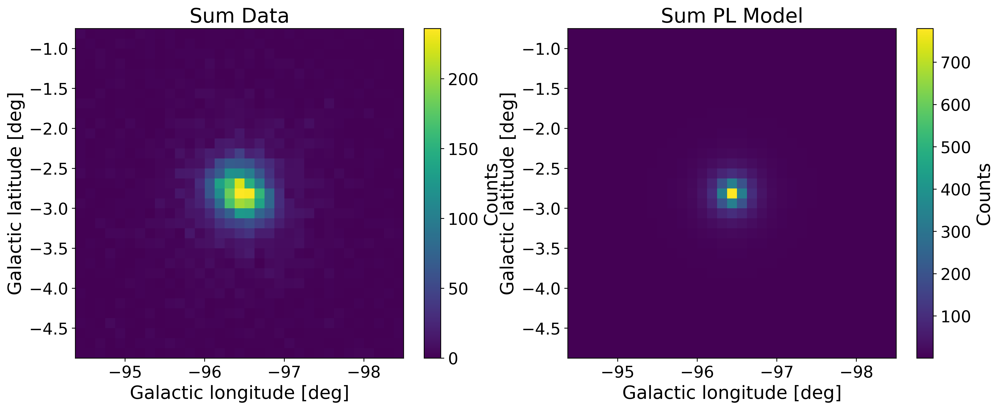

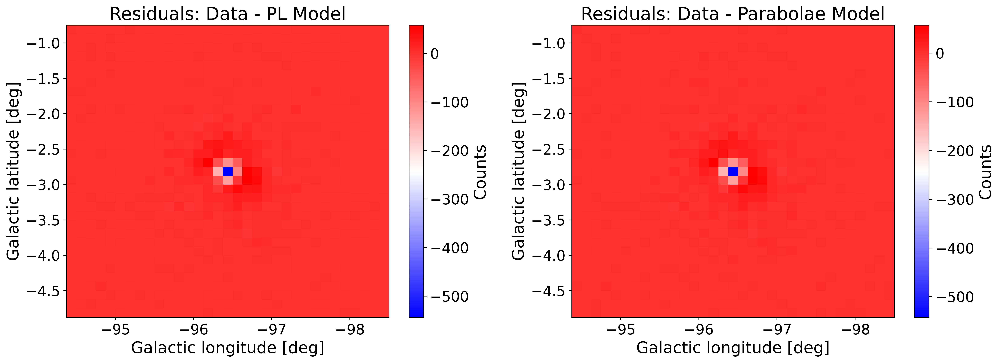

In [178]:
import matplotlib.pyplot as plt
import numpy as np

# Set global font sizes for all plots
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
    'figure.titlesize': 22
})

# Collapse energy axis
flight_data_allE = np.sum(flight_data_cube, axis=0)
model_PL_allE = np.sum(results['PL']['model'], axis=0)
model_parabolae_allE = np.sum(results['parabolae']['model'], axis=0)

# Debug
print(f"DEBUG : flight data allE shape : {flight_data_allE.shape}")
print(f"DEBUG : model PL allE shape : {model_PL_allE.shape}")
print(f"DEBUG : model parabolae allE shape : {model_parabolae_allE.shape}")

# First figure: Data & Models
fig1, axs1 = plt.subplots(1, 2, figsize=(16, 6))

# Common extent
extent = [
    np.rad2deg(roi_lon_edges[0]), np.rad2deg(roi_lon_edges[-1]),
    np.rad2deg(roi_lat_edges[0]), np.rad2deg(roi_lat_edges[-1])
]

# Data
im0 = axs1[0].imshow(
    flight_data_allE.T, origin='lower', extent=extent, aspect='auto'
)
axs1[0].set_title("Sum Data")
axs1[0].set_xlabel('Galactic longitude [deg]')
axs1[0].set_ylabel('Galactic latitude [deg]')
axs1[0].xaxis.set_inverted(True)
cbar0 = fig1.colorbar(im0, ax=axs1[0], orientation='vertical')
cbar0.ax.tick_params(labelsize=16)
cbar0.set_label('Counts', fontsize=18)

# PL Model
im1 = axs1[1].imshow(
    model_PL_allE.T, origin='lower', extent=extent, aspect='auto'
)
axs1[1].set_title("Sum PL Model")
axs1[1].set_xlabel('Galactic longitude [deg]')
axs1[1].set_ylabel('Galactic latitude [deg]')
axs1[1].xaxis.set_inverted(True)
cbar1 = fig1.colorbar(im1, ax=axs1[1], orientation='vertical')
cbar1.ax.tick_params(labelsize=16)
cbar1.set_label('Counts', fontsize=18)

# Second figure: Residuals
fig2, axs2 = plt.subplots(1, 2, figsize=(16, 6))

# Residuals (Data - PL Model)
residual_PL = flight_data_allE - model_PL_allE
im3 = axs2[0].imshow(
    residual_PL.T, origin='lower', extent=extent, aspect='auto', cmap='bwr'
)
axs2[0].set_title("Residuals: Data - PL Model")
axs2[0].set_xlabel('Galactic longitude [deg]')
axs2[0].set_ylabel('Galactic latitude [deg]')
axs2[0].xaxis.set_inverted(True)
cbar2 = fig2.colorbar(im3, ax=axs2[0], orientation='vertical')
cbar2.ax.tick_params(labelsize=16)
cbar2.set_label('Counts', fontsize=18)

# Residuals (Data - Parabolae Model)
residual_parabolae = flight_data_allE - model_parabolae_allE
im4 = axs2[1].imshow(
    residual_parabolae.T, origin='lower', extent=extent, aspect='auto', cmap='bwr'
)
axs2[1].set_title("Residuals: Data - Parabolae Model")
axs2[1].set_xlabel('Galactic longitude [deg]')
axs2[1].set_ylabel('Galactic latitude [deg]')
axs2[1].xaxis.set_inverted(True)
cbar3 = fig2.colorbar(im4, ax=axs2[1], orientation='vertical')
cbar3.ax.tick_params(labelsize=16)
cbar3.set_label('Counts', fontsize=18)

plt.tight_layout()
fig1.savefig(figPath+f"modelAndData_{target}.png")
plt.show()


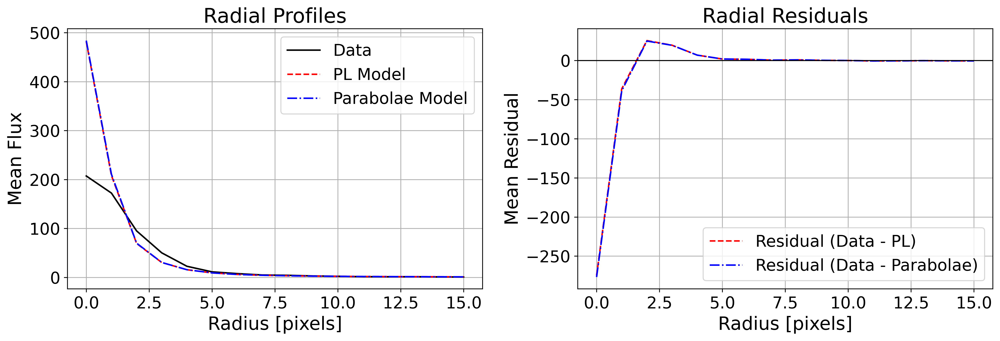

In [179]:
from scipy.ndimage import center_of_mass

# Compute total maps
flight_data_allE = np.sum(flight_data_cube, axis=0)
model_PL_allE = np.sum(results['PL']['model'], axis=0)
model_parabolae_allE = np.sum(results['parabolae']['model'], axis=0)

# Get image dimensions
ny, nx = flight_data_allE.shape
y, x = np.indices((ny, nx))

# Find center (assume center of mass of the data or geometric center)
cy, cx = center_of_mass(flight_data_allE)
# OR use geometric center:
# cy, cx = ny // 2, nx // 2

# Compute radial distance map
r = np.sqrt((x - cx)**2 + (y - cy)**2)

# Bin radial distances
r = r.astype(int)
r_max = np.min([ny, nx]) // 2

radial_profile_data = np.array([flight_data_allE[r == i].mean() for i in range(r_max)])
radial_profile_PL = np.array([model_PL_allE[r == i].mean() for i in range(r_max)])
radial_profile_parabolae = np.array([model_parabolae_allE[r == i].mean() for i in range(r_max)])
radial_profile_residual_PL = radial_profile_data - radial_profile_PL
radial_profile_residual_parabolae = radial_profile_data - radial_profile_parabolae

# Plot
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Left: Profiles
axs[0].plot(radial_profile_data, 'k-', label='Data')
axs[0].plot(radial_profile_PL, 'r--', label='PL Model')
axs[0].plot(radial_profile_parabolae, 'b-.', label='Parabolae Model')
axs[0].set_title("Radial Profiles")
axs[0].set_xlabel("Radius [pixels]")
axs[0].set_ylabel("Mean Flux")
axs[0].legend()
axs[0].grid(True)

# Right: Residuals
axs[1].plot(radial_profile_residual_PL, 'r--', label='Residual (Data - PL)')
axs[1].plot(radial_profile_residual_parabolae, 'b-.', label='Residual (Data - Parabolae)')
axs[1].axhline(0, color='k', lw=1)
axs[1].set_title("Radial Residuals")
axs[1].set_xlabel("Radius [pixels]")
axs[1].set_ylabel("Mean Residual")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

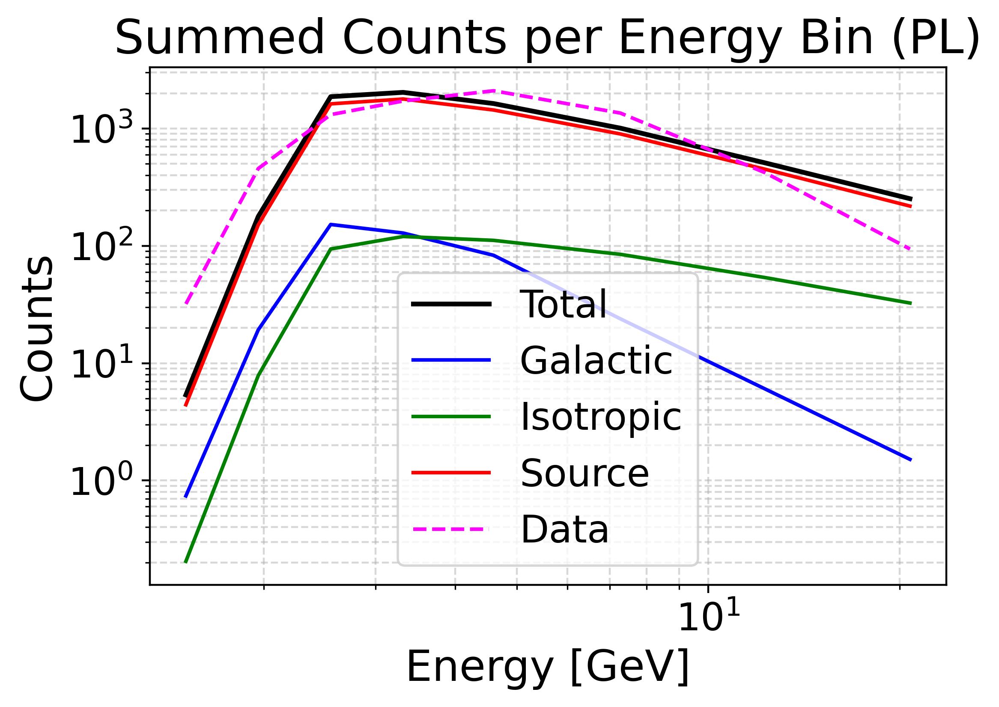

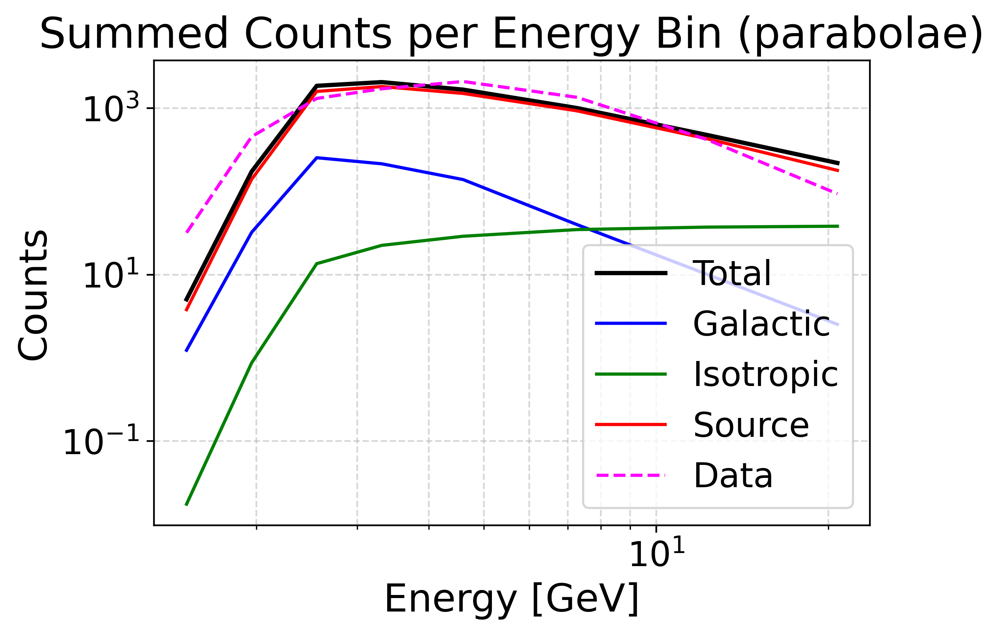

In [180]:
for model_type in ('PL', 'parabolae') :
    model = results[model_type]['model']
    model_gal = results[model_type]['model_gal']
    model_iso = results[model_type]['model_iso']
    model_src = results[model_type]['model_src']
# Sum over spatial dimensions (nY, nX)
    counts = model.sum(axis=(1, 2))
    counts_gal = model_gal.sum(axis=(1, 2))
    counts_iso = model_iso.sum(axis=(1, 2))
    counts_src = model_src.sum(axis=(1, 2))
    counts_data = total_data = flight_data_cube.sum(axis=(1,2))

    fig, ax = plt.subplots()

    # Plot on log-log scale
    ax.loglog(E_bin_centers_valid, counts, label='Total', color='k', lw=2)
    ax.loglog(E_bin_centers_valid, counts_gal, label='Galactic', color='b')
    ax.loglog(E_bin_centers_valid, counts_iso, label='Isotropic', color='g')
    ax.loglog(E_bin_centers_valid, counts_src, label='Source', color='r')
    ax.loglog(E_bin_centers_valid, counts_data, label='Data', ls='--', color = "magenta")

    ax.set_xlabel('Energy [GeV]')
    ax.set_ylabel('Counts')
    ax.set_title(f'Summed Counts per Energy Bin ({model_type})')
    ax.legend()
    ax.grid(True, which='both', ls='--', alpha=0.5)

    plt.show()

    

In [181]:

# --- Plot Data vs PL vs parabolae ---
n_bins = len(E_bin_centers_valid)
fig, axs = plt.subplots(n_bins, 3, figsize=(15, 4 * n_bins))

for idx in range(n_bins):
    energy = E_bin_centers_valid[idx]
    extent = [
        np.rad2deg(roi_lon_edges[0]), np.rad2deg(roi_lon_edges[-1]),
        np.rad2deg(roi_lat_edges[0]), np.rad2deg(roi_lat_edges[-1])
    ]

    # --- Data ---
    ax_data = axs[idx, 0]
    total_data = np.sum(flight_data_cube[idx])
    im_data = ax_data.imshow(
        flight_data_cube[idx].T, origin='lower',
        extent=extent, aspect='auto'
    )
    ax_data.set_title(f"Data (E={energy:.2f} GeV)\n{total_data:.0f} counts")
    ax_data.set_xlabel('Galactic longitude [deg]')
    ax_data.set_ylabel('Galactic latitude [deg]')
    ax_data.xaxis.set_inverted(True)
    fig.colorbar(im_data, ax=ax_data, orientation='vertical', fraction=0.046, pad=0.04)

    # --- Power-law Model ---
    ax_PL = axs[idx, 1]
    model_PL = results['PL']['model'][idx]
    total_PL = np.sum(model_PL)
    im_PL = ax_PL.imshow(
        model_PL.T, origin='lower',
        extent=extent, aspect='auto'
    )
    ax_PL.set_title(f"PL Model (E={energy:.2f} GeV)\n{total_PL:.0f} counts")
    ax_PL.set_xlabel('Galactic longitude [deg]')
    ax_PL.set_ylabel('Galactic latitude [deg]')
    ax_PL.xaxis.set_inverted(True)
    fig.colorbar(im_PL, ax=ax_PL, orientation='vertical', fraction=0.046, pad=0.04)

    # --- Parabolae Model ---
    ax_parabolae = axs[idx, 2]
    model_parabolae = results['parabolae']['model'][idx]
    total_parabolae = np.sum(model_parabolae)
    im_parabolae = ax_parabolae.imshow(
        model_parabolae.T, origin='lower',
        extent=extent, aspect='auto'
    )
    ax_parabolae.set_title(f"Parabolae Model (E={energy:.2f} GeV)\n{total_parabolae:.0f} counts")
    ax_parabolae.set_xlabel('Galactic longitude [deg]')
    ax_parabolae.set_ylabel('Galactic latitude [deg]')
    ax_parabolae.xaxis.set_inverted(True)
    fig.colorbar(im_parabolae, ax=ax_parabolae, orientation='vertical', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

<!-- ### Explore parameters space -->

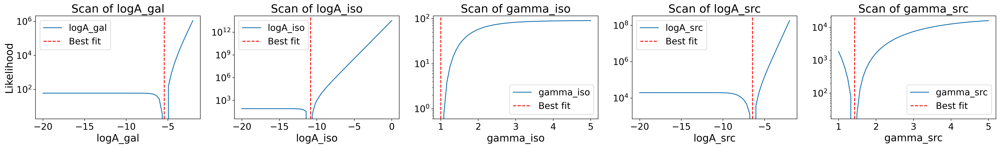

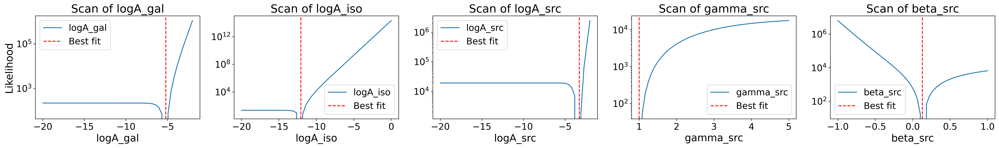

In [182]:
from matplotlib import cm

for model_type in ('PL', 'parabolae') :

    m = fit_results[model_type]['minuit']
    
    best_params = results[model_type]['params']
    if model_type == 'PL' : 
        neg_log_likelihood = neg_log_likelihood_PL
        param_names = ['logA_gal', 'logA_iso', 'gamma_iso', 'logA_src', 'gamma_src']
    elif model_type == 'parabolae':
        neg_log_likelihood = neg_log_likelihood_parabolae
        param_names = ['logA_gal', 'logA_iso', 'logA_src', 'gamma_src', 'beta_src']
    param_bounds = m.limits

    fig, axs = plt.subplots(1, len(param_names), figsize=(5 * len(param_names), 4), sharey=False)

    for param_idx, (name, bounds) in enumerate(zip(param_names, param_bounds)):
        scan_values = np.linspace(bounds[0], bounds[1], 50)
        nl_values = []
        for v in scan_values:
            p = list(best_params)
            p[param_idx] = v
            nll = neg_log_likelihood(*p)
            nl_values.append(nll)
        ax = axs[param_idx]
        ax.plot(scan_values, nl_values + np.abs(np.min(nl_values)), label=name)
        ax.set_yscale('log')
        ax.axvline(best_params[param_idx], color='red', linestyle='--', label='Best fit')
        ax.set_xlabel(name)
        if param_idx == 0:
            ax.set_ylabel('Likelihood')
        ax.legend()
        ax.set_title(f"Scan of {name}")

    plt.tight_layout()
    plt.show()



    n_params = len(param_names)
    scan_points = 40  # number of scan points per parameter

    # Define scan ranges for each parameter (use m.limits)
    scan_ranges = [np.linspace(bounds[0], bounds[1], scan_points) for bounds in param_bounds]

    # Prepare figure
    fig, axes = plt.subplots(n_params, n_params, figsize=(4*n_params, 4*n_params), squeeze=False)

    for i in range(n_params):
        for j in range(n_params):
            ax = axes[i, j]
            if i > j:
                # Scan over param i (y-axis) and param j (x-axis)
                p1_vals = scan_ranges[j]
                p2_vals = scan_ranges[i]
                Z = np.zeros((len(p2_vals), len(p1_vals)))
                for y, v2 in enumerate(p2_vals):
                    for x, v1 in enumerate(p1_vals):
                        p = best_params.copy()
                        p[j] = v1
                        p[i] = v2
                        nll = neg_log_likelihood(*p)
                        Z[y, x] = (nll)
                P1, P2 = np.meshgrid(p1_vals, p2_vals)
                im = ax.contourf(P1, P2, Z + 1.01*np.abs(np.min(Z)), levels=30, cmap=cm.viridis, norm=LogNorm())
                ax.scatter(best_params[j], best_params[i], color='red', s=30)
                ax.set_xlabel(param_names[j])
                ax.set_ylabel(param_names[i])
            elif i == j:
                # 1D scan (diagonal): plot NLL vs parameter
                scan_vals = scan_ranges[i]
                nl_vals = []
                for v in scan_vals:
                    p = best_params.copy()
                    p[i] = v
                    nll = neg_log_likelihood(*p)
                    nl_vals.append(nll)
                ax.plot(scan_vals, (nl_vals + np.abs(np.min(nl_vals))))
                ax.axvline(best_params[i], color='red', linestyle='--')
                ax.set_xlabel(param_names[i])
                ax.set_yscale('log')
                ax.set_ylabel('Likelihood')
            else:
                ax.axis('off')

    plt.tight_layout()
    plt.show()

In [183]:
# %pip install emcee
# %pip install corner

Best params: [-5.215469823911964, -12.07703576134499, -3.2906179588779327, 1.0000000024140903, 0.1294009669315126]
Best params: [-5.439410903157743, -10.830223506356813, 1.0000805965491077, -6.448841897887816, 1.4285303587844655]
Testing likelihood function...
Likelihood at best params: -4745.923329551851
Likelihood function working correctly, starting MCMC...


  0%|                                                             | 0/1000 [00:00<?, ?it/s]/home/users/l/lebrun/.local/lib/python3.9/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in double_scalars
  lnpdiff = f + nlp - state.log_prob[j]
100%|█████████████████████████████████████████████████| 1000/1000 [00:01<00:00, 565.34it/s]


Mean acceptance fraction: 0.005
Final sample shape: (25600, 5)


Running MCMC diagnostics...
=== MCMC Diagnostics ===
Acceptance fractions: [0.003 0.011 0.012 0.    0.002 0.01  0.015 0.009 0.018 0.004 0.004 0.
 0.009 0.    0.    0.    0.017 0.    0.006 0.    0.011 0.    0.    0.006
 0.005 0.    0.    0.    0.014 0.008 0.    0.   ]
Mean acceptance fraction: 0.005
Std acceptance fraction: 0.006
Full chain shape: (1000, 32, 5)


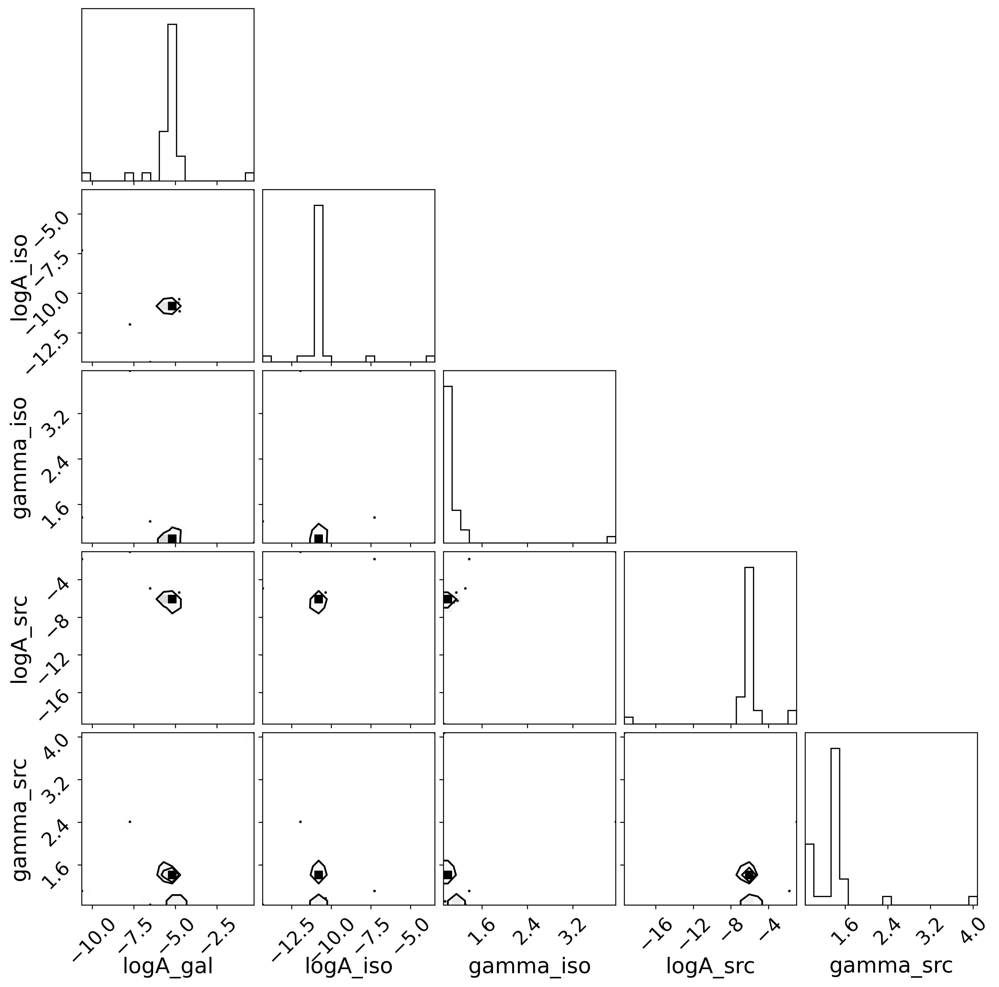

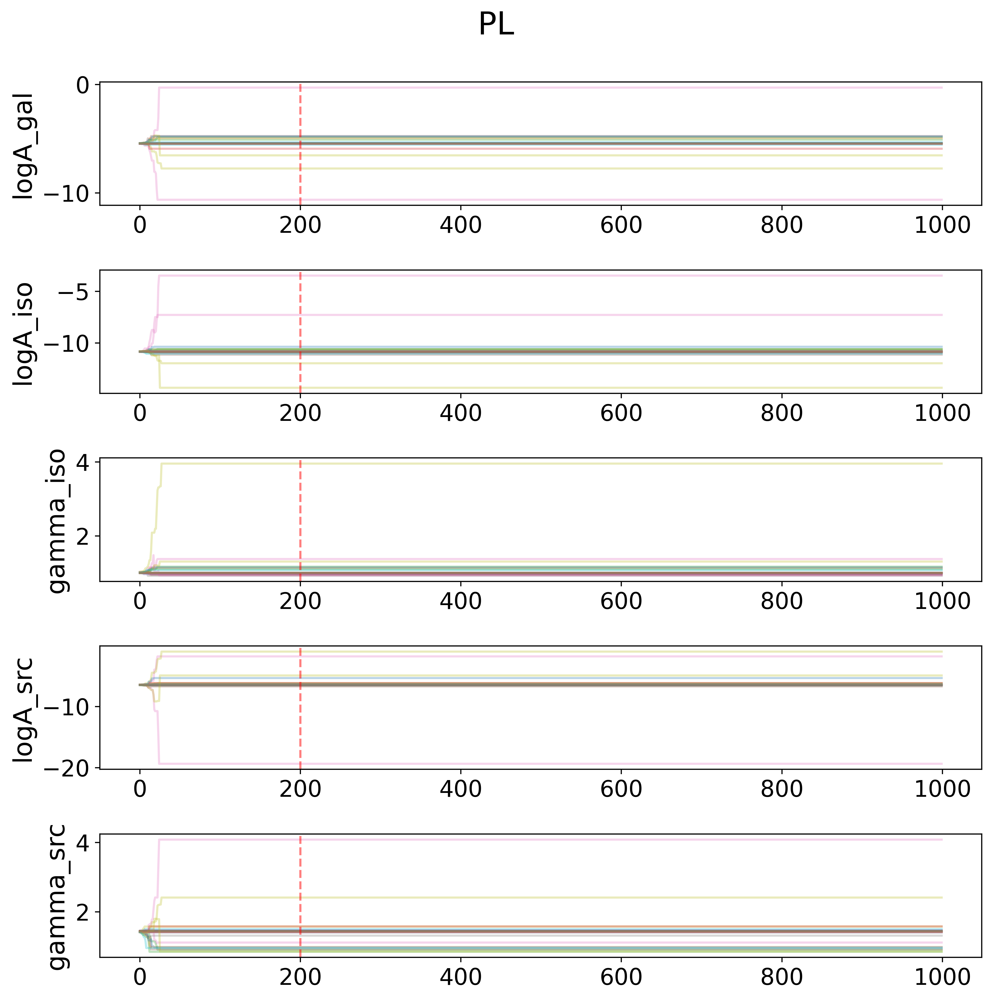

Samples after burn-in: (25600, 5)

=== Parameter Statistics ===
logA_gal:
  Mean: -5.4738
  Std:  1.3911
  Min:  -10.6289
  Max:  -0.2782
  Range: 10.3506
logA_iso:
  Mean: -10.6217
  Std:  1.5771
  Min:  -14.3333
  Max:  -3.4633
  Range: 10.8700
gamma_iso:
  Mean: 1.1234
  Std:  0.5174
  Min:  0.9211
  Max:  3.9534
  Range: 3.0324
logA_src:
  Mean: -6.4423
  Std:  2.6319
  Min:  -19.3513
  Max:  -1.0087
  Range: 18.3426
gamma_src:
  Mean: 1.4330
  Std:  0.5589
  Min:  0.8471
  Max:  4.0819
  Range: 3.2348
PLOTTING IMPROVED CORNER PLOT

=== Corner Plot Info ===
Number of samples: 25600


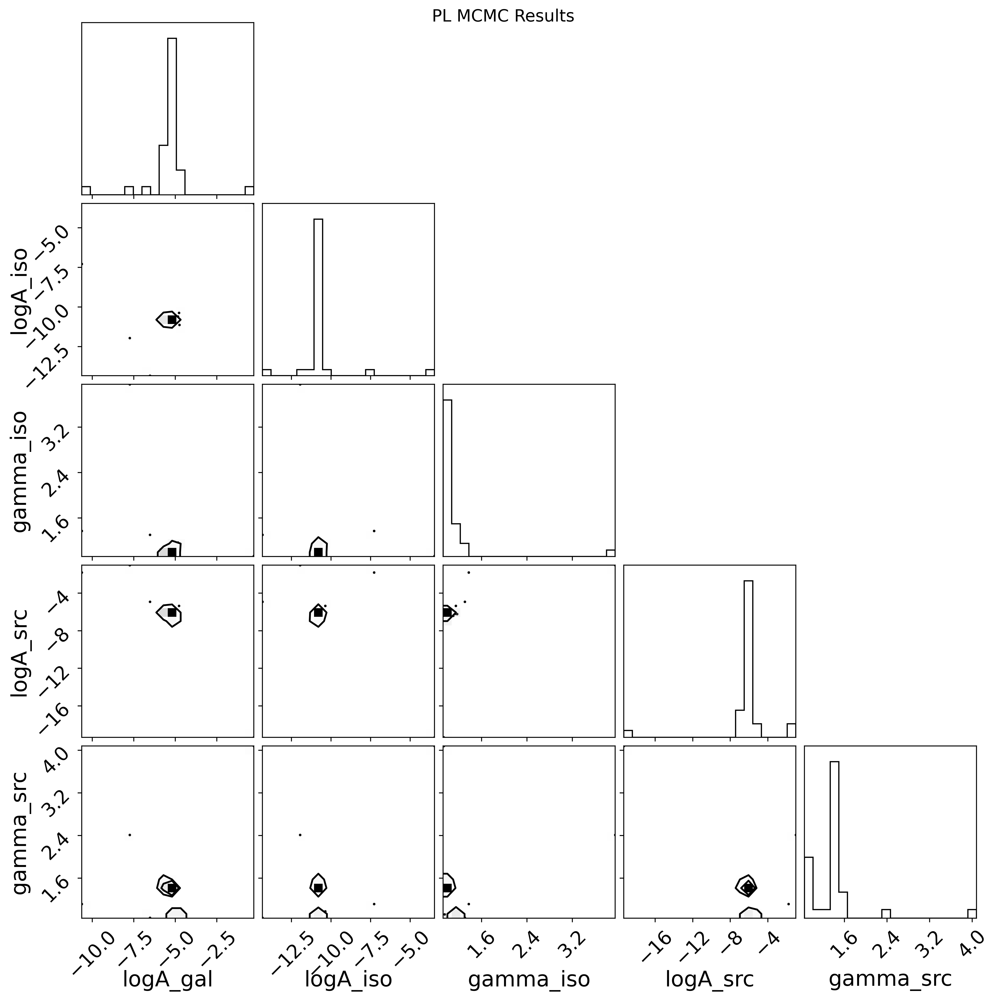

Analyzing tight clusters...
=== Well-Constrained Parameter Analysis ===

logA_gal:
  Best fit: -5.439411
  MCMC mean: -5.473790 ± 1.391065
  MCMC median: -5.434448
  68% CI: [-5.476445, -5.084091]
  95% CI: [-10.628873, -0.278239]
  Relative uncertainty: 25.41%

logA_iso:
  Best fit: -10.830224
  MCMC mean: -10.621663 ± 1.577060
  MCMC median: -10.832508
  68% CI: [-10.910536, -10.637230]
  95% CI: [-14.333307, -3.463318]
  Relative uncertainty: 14.85%

gamma_iso:
  Best fit: 1.000081
  MCMC mean: 1.123445 ± 0.517437
  MCMC median: 1.000000
  68% CI: [0.986624, 1.136273]
  95% CI: [0.921073, 3.953444]
  Relative uncertainty: 46.06%

logA_src:
  Best fit: -6.448842
  MCMC mean: -6.442252 ± 2.631894
  MCMC median: -6.443820
  68% CI: [-6.494381, -6.183946]
  95% CI: [-19.351330, -1.008726]
  Relative uncertainty: 40.85%

gamma_src:
  Best fit: 1.428530
  MCMC mean: 1.433021 ± 0.558920
  MCMC median: 1.431001
  68% CI: [0.975986, 1.467173]
  95% CI: [0.847145, 4.081948]
  Relative uncerta

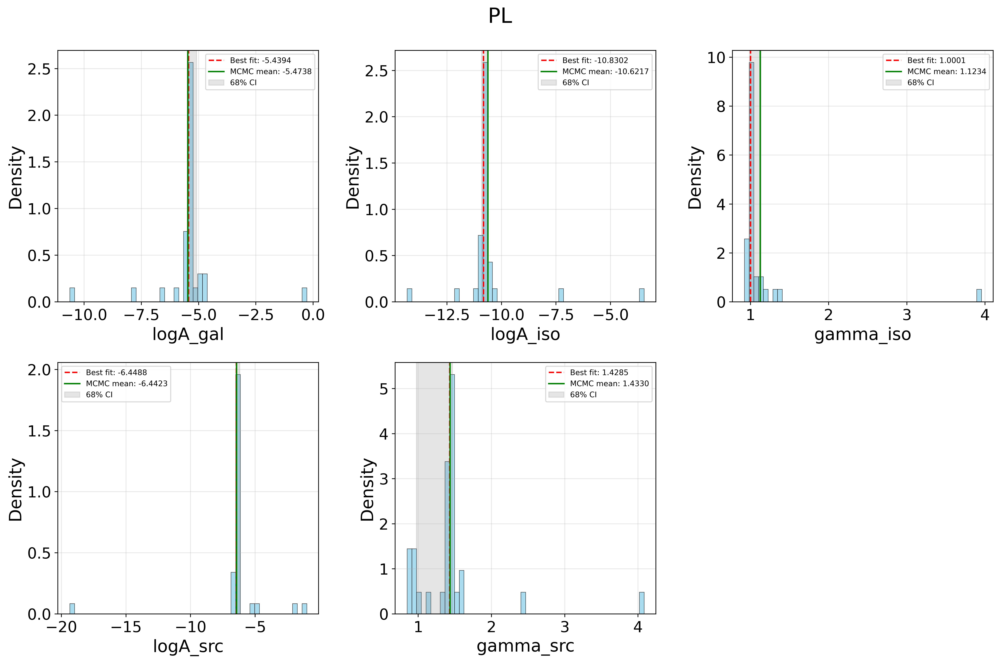

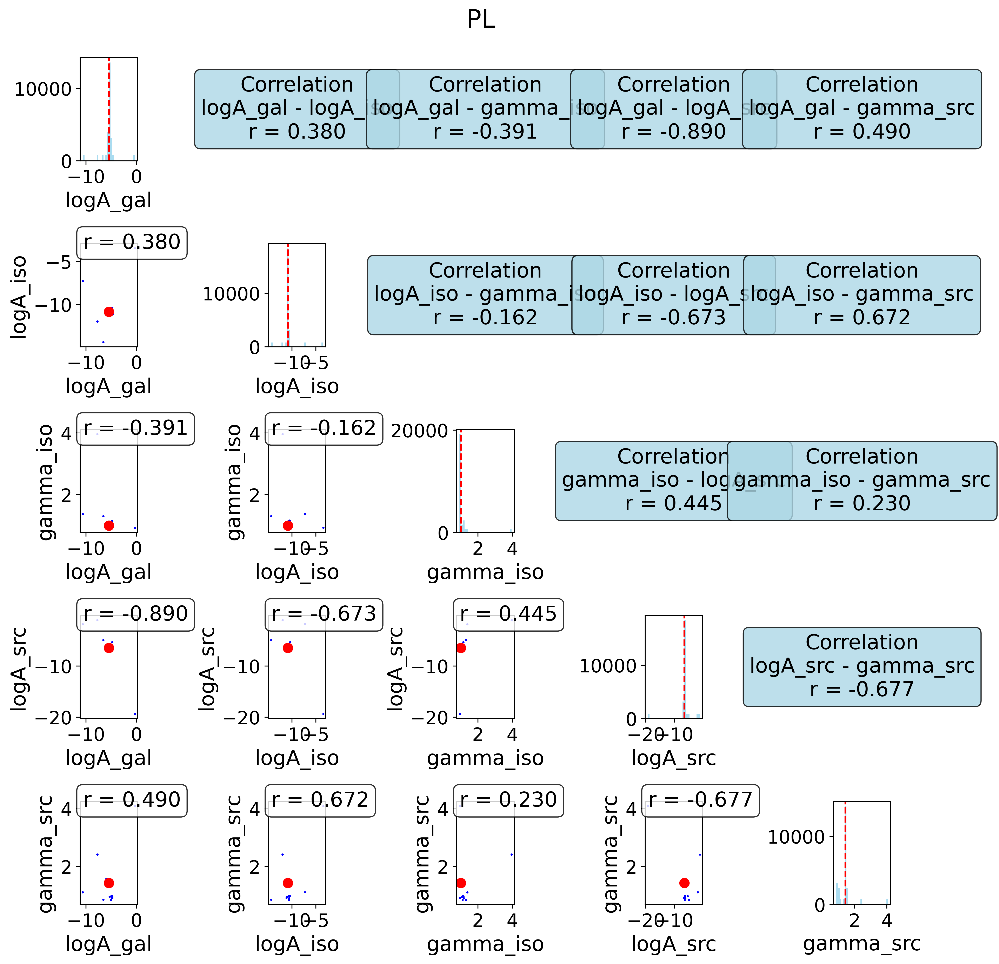


Attempting clusters corner plot...


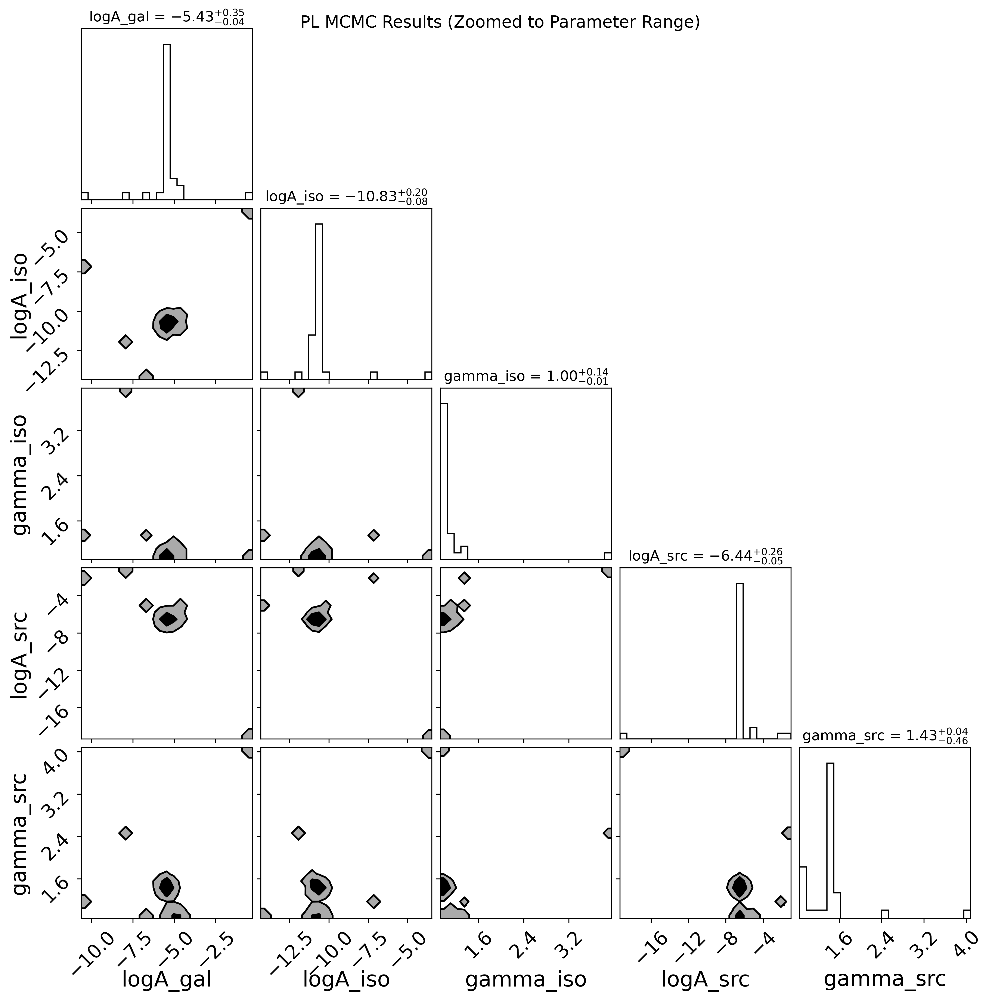

Corner plot created successfully!

Checking constraints...

=== Parameter Constraint Analysis ===

logA_gal:
  Parameter range: 10.350634
  Standard deviation: 1.391065
  Range/std ratio: 7.44

logA_iso:
  Parameter range: 10.869989
  Standard deviation: 1.577060
  Range/std ratio: 6.89
  → WARNING: Might be hitting prior boundaries

gamma_iso:
  Parameter range: 3.032371
  Standard deviation: 0.517437
  Range/std ratio: 5.86

logA_src:
  Parameter range: 18.342604
  Standard deviation: 2.631894
  Range/std ratio: 6.97
  → WARNING: Might be hitting prior boundaries

gamma_src:
  Parameter range: 3.234803
  Standard deviation: 0.558920
  Range/std ratio: 5.79
Best params: [-5.439410903157743, -10.830223506356813, 1.0000805965491077, -6.448841897887816, 1.4285303587844655]
Best params: [-5.215469823911964, -12.07703576134499, -3.2906179588779327, 1.0000000024140903, 0.1294009669315126]
Testing likelihood function...
Likelihood at best params: -4765.037895605904
Likelihood function workin

100%|█████████████████████████████████████████████████| 1000/1000 [00:01<00:00, 555.19it/s]


Mean acceptance fraction: 0.008
Final sample shape: (25600, 5)


Running MCMC diagnostics...
=== MCMC Diagnostics ===
Acceptance fractions: [0.003 0.001 0.    0.014 0.018 0.    0.    0.003 0.006 0.005 0.    0.028
 0.    0.002 0.    0.    0.    0.014 0.003 0.    0.021 0.013 0.006 0.
 0.    0.008 0.028 0.031 0.033 0.    0.003 0.005]
Mean acceptance fraction: 0.008
Std acceptance fraction: 0.010
Full chain shape: (1000, 32, 5)


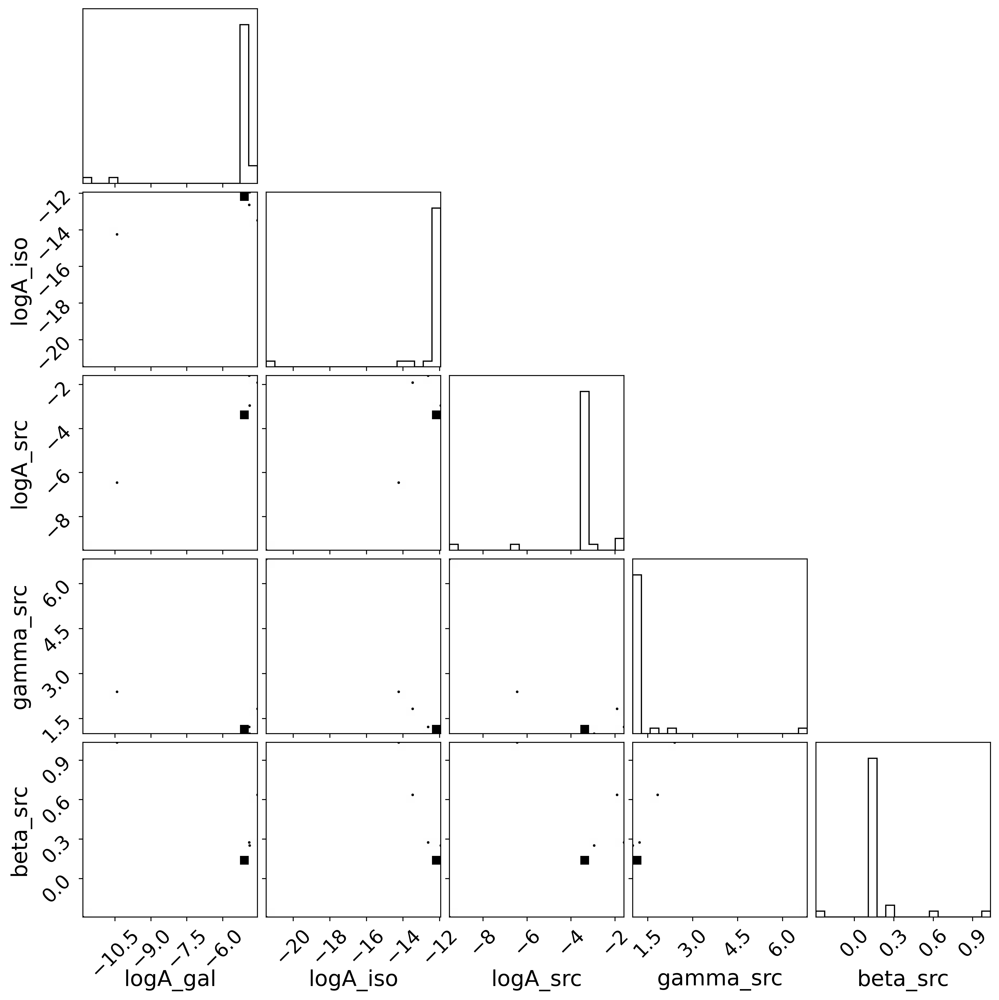

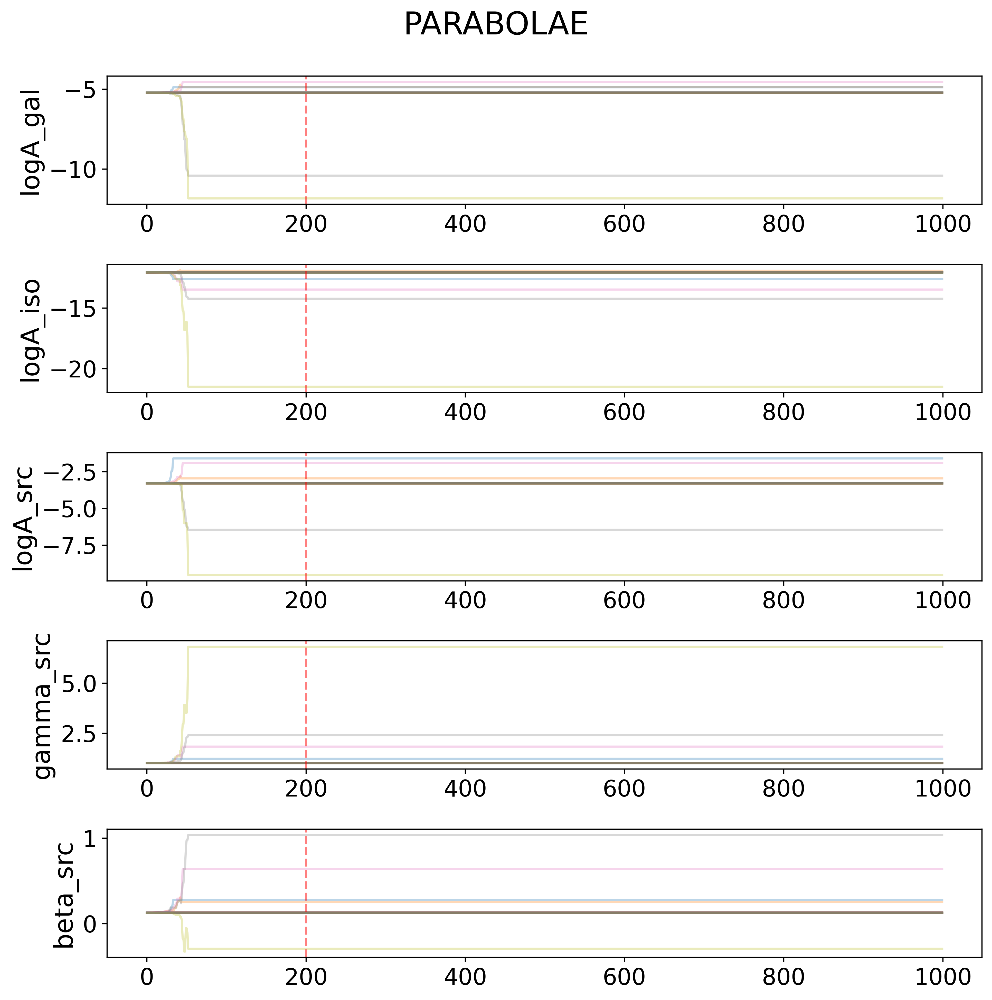

Samples after burn-in: (25600, 5)

=== Parameter Statistics ===
logA_gal:
  Mean: -5.5429
  Std:  1.4599
  Min:  -11.8409
  Max:  -4.5459
  Range: 7.2950
logA_iso:
  Mean: -12.4945
  Std:  1.6755
  Min:  -21.4797
  Max:  -11.9429
  Range: 9.5368
logA_src:
  Mean: -3.4775
  Std:  1.2828
  Min:  -9.5261
  Max:  -1.5919
  Range: 7.9342
gamma_src:
  Mean: 1.2581
  Std:  1.0379
  Min:  0.9958
  Max:  6.8236
  Range: 5.8278
beta_src:
  Mean: 0.1687
  Std:  0.1970
  Min:  -0.2914
  Max:  1.0352
  Range: 1.3266
PLOTTING IMPROVED CORNER PLOT

=== Corner Plot Info ===
Number of samples: 25600


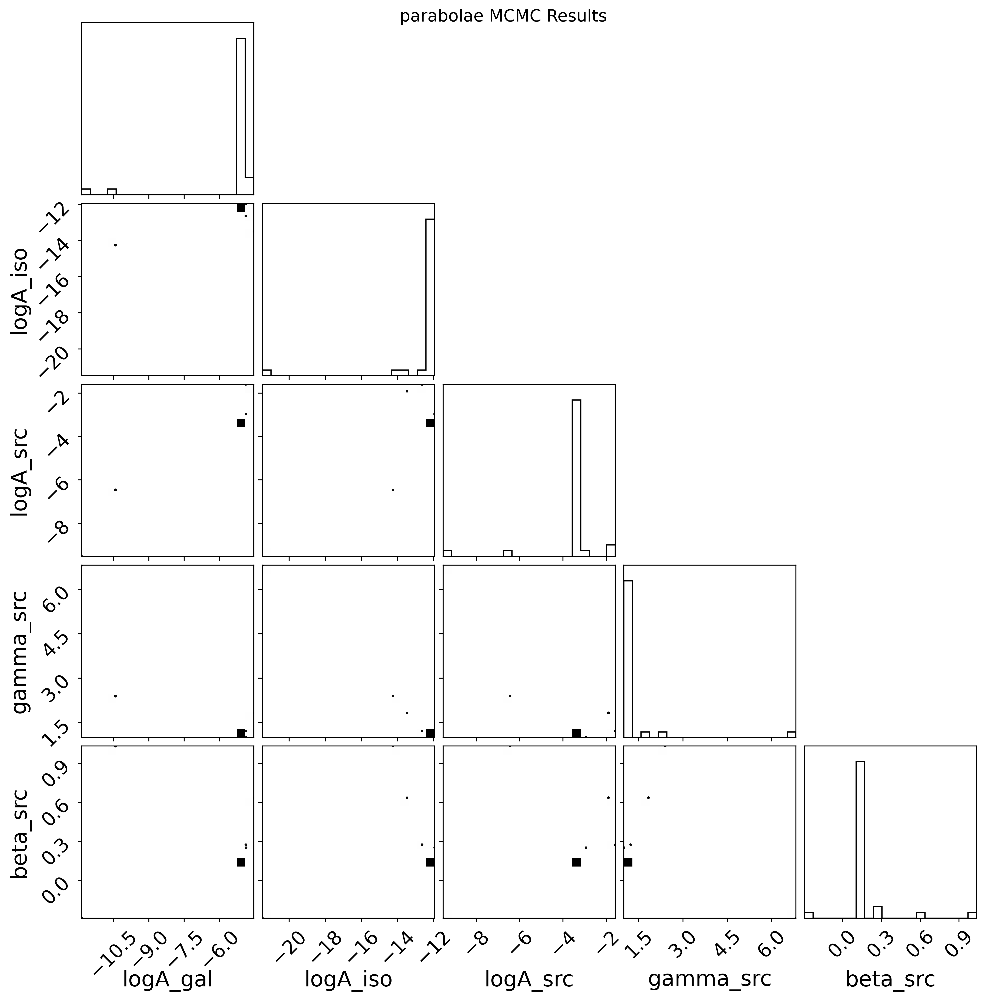

Analyzing tight clusters...
=== Well-Constrained Parameter Analysis ===

logA_gal:
  Best fit: -5.215470
  MCMC mean: -5.542901 ± 1.459879
  MCMC median: -5.215464
  68% CI: [-5.215748, -5.214938]
  95% CI: [-11.840890, -4.545916]
  Relative uncertainty: 26.34%

logA_iso:
  Best fit: -12.077036
  MCMC mean: -12.494503 ± 1.675495
  MCMC median: -12.077076
  68% CI: [-12.077529, -12.075325]
  95% CI: [-21.479664, -11.942851]
  Relative uncertainty: 13.41%

logA_src:
  Best fit: -3.290618
  MCMC mean: -3.477532 ± 1.282795
  MCMC median: -3.290677
  68% CI: [-3.291917, -3.290101]
  95% CI: [-9.526060, -1.591875]
  Relative uncertainty: 36.89%

gamma_src:
  Best fit: 1.000000
  MCMC mean: 1.258104 ± 1.037881
  MCMC median: 0.999991
  68% CI: [0.999538, 1.000000]
  95% CI: [0.995813, 6.823633]
  Relative uncertainty: 82.50%

beta_src:
  Best fit: 0.129401
  MCMC mean: 0.168742 ± 0.197016
  MCMC median: 0.129394
  68% CI: [0.128538, 0.131525]
  95% CI: [-0.291419, 1.035197]
  Relative uncerta

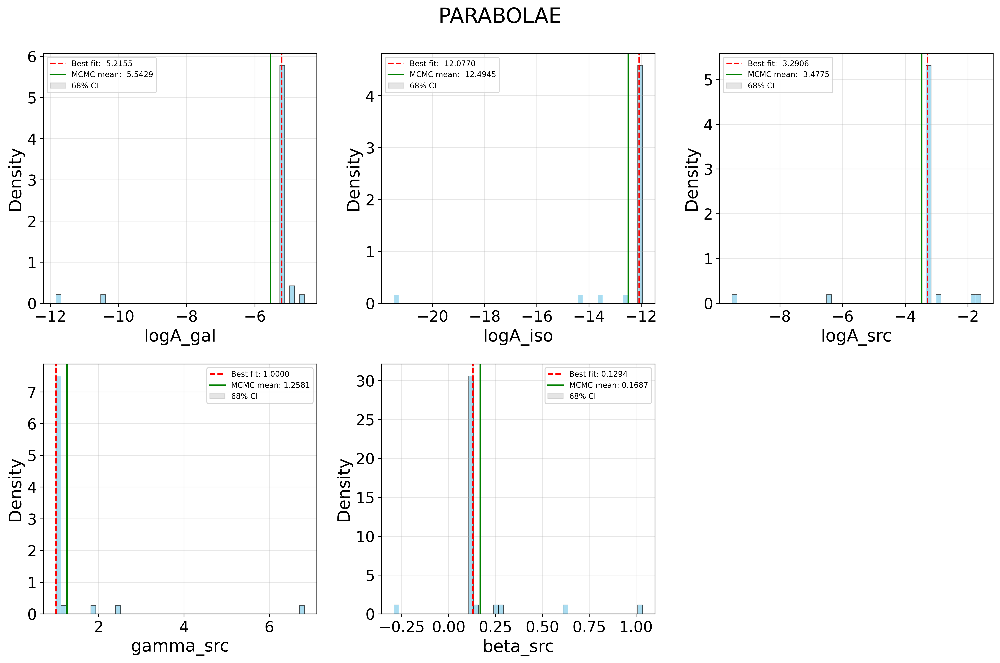

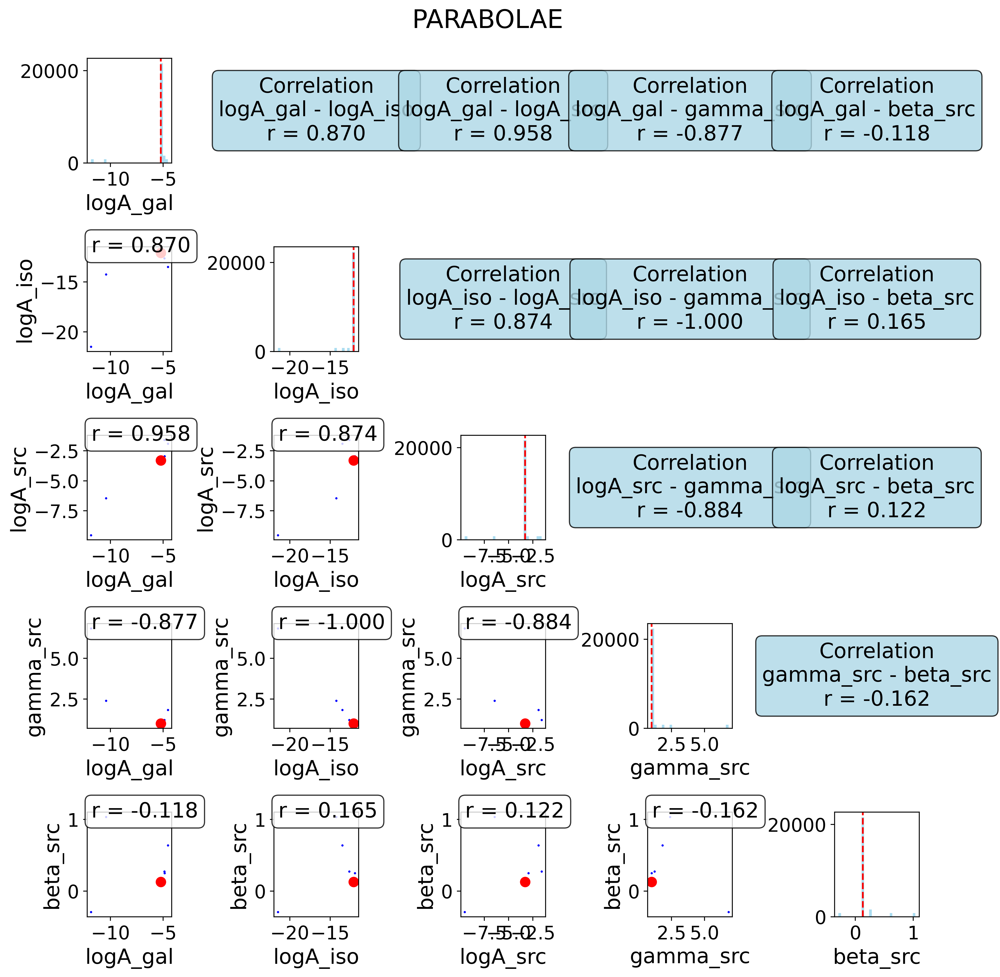


Attempting clusters corner plot...


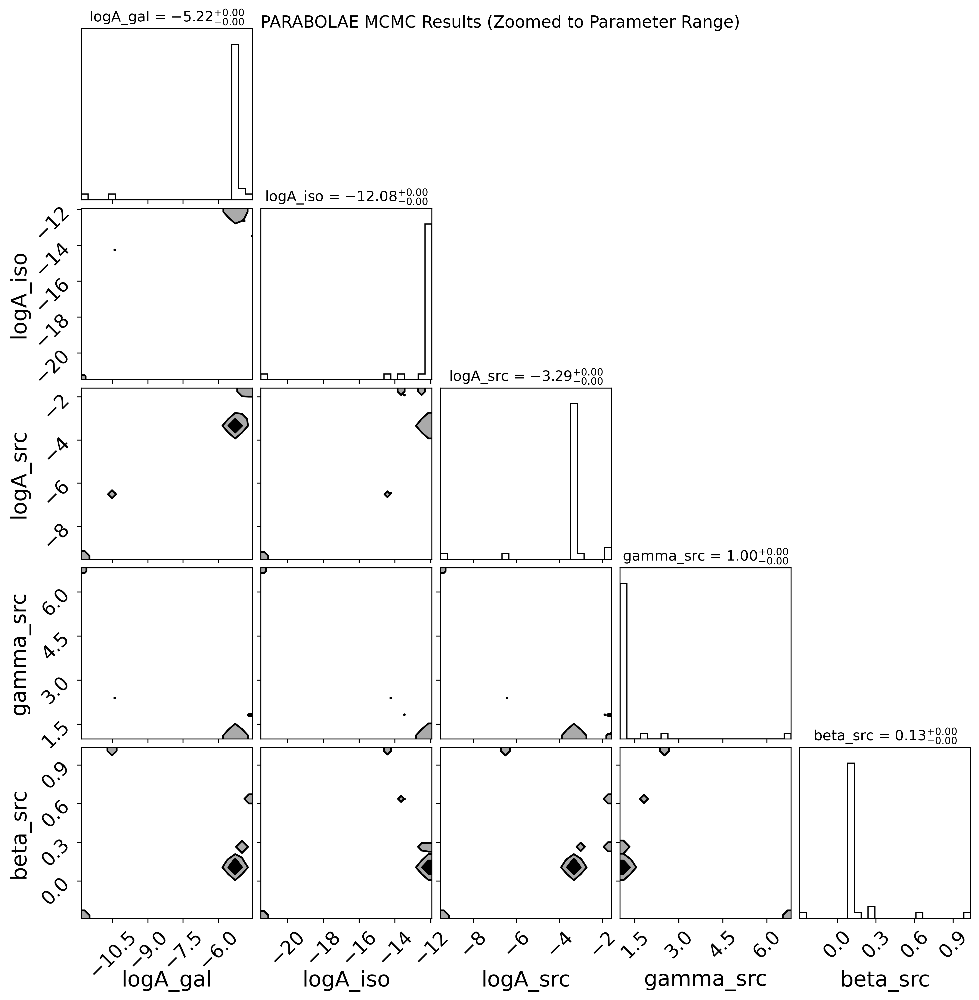

Corner plot created successfully!

Checking constraints...

=== Parameter Constraint Analysis ===

logA_gal:
  Parameter range: 7.294974
  Standard deviation: 1.459879
  Range/std ratio: 5.00

logA_iso:
  Parameter range: 9.536814
  Standard deviation: 1.675495
  Range/std ratio: 5.69
  → WARNING: Might be hitting prior boundaries

logA_src:
  Parameter range: 7.934184
  Standard deviation: 1.282795
  Range/std ratio: 6.19

gamma_src:
  Parameter range: 5.827820
  Standard deviation: 1.037881
  Range/std ratio: 5.62
  → WARNING: Might be hitting prior boundaries

beta_src:
  Parameter range: 1.326616
  Standard deviation: 0.197016
  Range/std ratio: 6.73


In [184]:
import emcee, corner
import numpy as np

m_PL = fit_results['PL']['minuit']
m_par = fit_results['parabolae']['minuit']

def neg_log_likelihood_emcee_PL(params):
    """Wrapper for emcee with error handling and priors"""
    try:
        # Unpack parameters
        logA_gal, logA_iso, gamma_iso, logA_src, gamma_src = params

        (logA_gal_l, logA_gal_u), (logA_iso_l, logA_iso_u), (gamma_iso_l, gamma_iso_u), (logA_src_l, logA_src_u), (gamma_src_l, gamma_src_u) = m_PL.limits
        if not (logA_gal_l < logA_gal < logA_gal_u and logA_iso_l < logA_iso < logA_iso_u and logA_src_l < logA_src < logA_src_u):
            return np.inf
        if not ( gamma_src_l < gamma_src < gamma_src_u and gamma_iso_l < gamma_iso < gamma_iso_u):
            return np.inf
        
        # Call your original function
        result = neg_log_likelihood_PL(*params)
        
        # Check for NaN or infinite values
        if np.isnan(result) or np.isinf(result):
            return np.inf
            
        return result
        
    except (ValueError, RuntimeWarning, FloatingPointError):
        # Return positive infinity for any numerical errors
        return np.inf
    
def neg_log_likelihood_emcee_par(params):
    """Wrapper for emcee with error handling and priors"""
    try:
        # Unpack parameters
        logA_gal, logA_iso, logA_src, gamma_src, beta_src = params

        (logA_gal_l, logA_gal_u), (logA_iso_l, logA_iso_u), (logA_src_l, logA_src_u), (gamma_src_l, gamma_src_u), (beta_src_l, beta_src_u) = m_par.limits
        
        if not (logA_gal_l < logA_gal < logA_gal_u and logA_iso_l < logA_iso < logA_iso_u and logA_src_l < logA_src < logA_src_u):
            return np.inf
        if not (gamma_src_l < gamma_src < gamma_src_u):
            return np.inf
        if not (beta_src_l < beta_src < beta_src_u):
            return np.inf
        
        # Call your original function
        result = neg_log_likelihood_parabolae(*params)
        
        # Check for NaN or infinite values
        if np.isnan(result) or np.isinf(result):
            return np.inf
            
        return result
        
    except (ValueError, RuntimeWarning, FloatingPointError):
        # Return positive infinity for any numerical errors
        return np.inf
# Better initialization strategy
def initialize_walkers_PL(best_params, nwalkers, scale=1e-2):
    """Initialize walkers with smaller perturbations and bounds checking"""
    ndim = len(best_params)
    p0 = []
    (logA_gal_l, logA_gal_u), (logA_iso_l, logA_iso_u), (gamma_iso_l, gamma_iso_u), (logA_src_l, logA_src_u), (gamma_src_l, gamma_src_u) = m_PL.limits

    for i in range(nwalkers):
        # Start with smaller perturbations
        walker = np.array(best_params) + scale * np.random.randn(ndim)
        

        # Ensure walkers start in reasonable parameter space
        # Adjust these bounds based on your problem
        walker[0] = np.clip(walker[0], logA_gal_l, logA_gal_u)  # logA_gal
        walker[1] = np.clip(walker[1], logA_iso_l, logA_iso_u)  # logA_iso  
        walker[2] = np.clip(walker[2], gamma_iso_l, gamma_iso_u)  # gamma_iso  
        walker[3] = np.clip(walker[3], logA_src_l, logA_src_u)  # logA_src
        walker[4] = np.clip(walker[4], gamma_src_l, gamma_src_u)  # gamma_src
        
        p0.append(walker)
    
    return p0
def initialize_walkers_par(best_params, nwalkers, scale=1e-4):
    """Initialize walkers with smaller perturbations and bounds checking"""
    ndim = len(best_params)
    p0 = []
    (logA_gal_l, logA_gal_u), (logA_iso_l, logA_iso_u), (logA_src_l, logA_src_u), (gamma_src_l, gamma_src_u), (beta_src_l, beta_src_u) = m_par.limits
        
    for i in range(nwalkers):
        # Start with smaller perturbations
        walker = np.array(best_params) + scale * np.random.randn(ndim)
        

        # Ensure walkers start in reasonable parameter space
        # Adjust these bounds based on your problem
        walker[0] = np.clip(walker[0], logA_gal_l, logA_gal_u)  # logA_gal
        walker[1] = np.clip(walker[1], logA_iso_l, logA_iso_u)  # logA_iso  
        walker[2] = np.clip(walker[2], logA_src_l, logA_src_u)  # logA_src
        walker[3] = np.clip(walker[3], gamma_src_l, gamma_src_u)  # gamma_src
        walker[4] = np.clip(walker[4], beta_src_l, beta_src_u)  # beta_src
        
        p0.append(walker)
    
    return p0


# After running your MCMC (using the previous robust version)
# Let's add diagnostics and solutions

def diagnose_mcmc(sampler, param_names, model_type, discard=200):
    """Diagnose MCMC performance and samples"""
    
    print("=== MCMC Diagnostics ===")
    
    # 1. Check acceptance fractions
    acc_fractions = sampler.acceptance_fraction
    print(f"Acceptance fractions: {acc_fractions}")
    print(f"Mean acceptance fraction: {np.mean(acc_fractions):.3f}")
    print(f"Std acceptance fraction: {np.std(acc_fractions):.3f}")
    
    # Ideal acceptance fraction is ~0.2-0.5
    if np.mean(acc_fractions) < 0.1:
        print("WARNING: Very low acceptance rate - consider smaller step sizes")
    elif np.mean(acc_fractions) > 0.7:
        print("WARNING: Very high acceptance rate - consider larger step sizes")
    
    # 2. Check chain convergence
    samples = sampler.get_chain()
    print(f"Full chain shape: {samples.shape}")
    
    # Plot chains to check convergence
    fig, axes = plt.subplots(len(param_names), figsize=(10, 2*len(param_names)))
    for i, name in enumerate(param_names):
        ax = axes[i] if len(param_names) > 1 else axes
        ax.plot(samples[:, :, i], alpha=0.3)
        ax.set_ylabel(name)
        ax.axvline(discard, color='red', linestyle='--', alpha=0.5)
    fig.suptitle(model_type.upper())
    plt.tight_layout()
    plt.show()
    
    # 3. Get samples after burn-in
    samples_flat = sampler.get_chain(discard=discard, flat=True)
    print(f"Samples after burn-in: {samples_flat.shape}")
    
    # 4. Check parameter ranges
    print("\n=== Parameter Statistics ===")
    for i, name in enumerate(param_names):
        param_samples = samples_flat[:, i]
        print(f"{name}:")
        print(f"  Mean: {np.mean(param_samples):.4f}")
        print(f"  Std:  {np.std(param_samples):.4f}")
        print(f"  Min:  {np.min(param_samples):.4f}")
        print(f"  Max:  {np.max(param_samples):.4f}")
        print(f"  Range: {np.max(param_samples) - np.min(param_samples):.4f}")
    
    return samples_flat

def improved_corner_plot(samples, param_names, model_type, title="MCMC Results"):
    """Create corner plot with better handling of sparse samples"""
    
    print(f"\n=== Corner Plot Info ===")
    print(f"Number of samples: {len(samples)}")
    
    # Check if we have enough samples
    if len(samples) < 100:
        print("WARNING: Very few samples - consider running longer chains")
        return None
    
    # Try different approaches based on sample size
    try:
        if len(samples) < 1000:
            # For sparse samples, reduce the number of contour levels
            fig = corner.corner(samples, labels=param_names, 
                              levels=[0.68, 0.95],  # Only 1σ and 2σ contours
                              bins=15,  # Fewer bins
                              smooth=0.5,  # Light smoothing
                              title_kwargs={"fontsize": 12})
        else:
            # Standard corner plot for sufficient samples
            fig = corner.corner(samples, labels=param_names,
                              title_kwargs={"fontsize": 12})
        
        fig.suptitle(model_type + ' ' +  title, fontsize=14)
        plt.show()
        return fig
        
    except Exception as e:
        print(f"Corner plot failed: {e}")
        
        # Fallback: simple parameter distributions
        n_params = len(param_names)
        fig, axes = plt.subplots(n_params, n_params, figsize=(12, 12))
        
        for i in range(n_params):
            for j in range(n_params):
                ax = axes[i, j]
                if i == j:
                    # Diagonal: histograms
                    ax.hist(samples[:, i], bins=20, alpha=0.7)
                    ax.set_xlabel(param_names[i])
                elif i > j:
                    # Lower triangle: scatter plots
                    ax.scatter(samples[:, j], samples[:, i], alpha=0.5, s=1)
                    ax.set_xlabel(param_names[j])
                    ax.set_ylabel(param_names[i])
                else:
                    # Upper triangle: empty
                    ax.axis('off')
        fig.suptitle(model_type.upper())
        plt.tight_layout()
        plt.show()
        return fig

# Example of running a longer chain with better initialization:
def run_longer_chain(best_params, param_names, nsteps=5000):
    """Run a longer chain with adaptive initialization"""
    
    nwalkers = 32
    ndim = len(best_params)
    
    # Try different initialization scales
    scales = [1e-5, 1e-4, 1e-3, 1e-2]
    
    for scale in scales:
        print(f"\nTrying initialization scale: {scale}")
        
        try:
            p0 = initialize_walkers(best_params, nwalkers, scale=scale)
            sampler = emcee.EnsembleSampler(nwalkers, ndim, neg_log_likelihood_emcee)
            
            # Run a short test
            sampler.run_mcmc(p0, 100, progress=False)
            
            # Check acceptance rate
            acc_rate = np.mean(sampler.acceptance_fraction)
            print(f"Acceptance rate: {acc_rate:.3f}")
            
            if 0.15 < acc_rate < 0.65:  # Good acceptance rate
                print("Good acceptance rate, running full chain...")
                sampler.reset()
                sampler.run_mcmc(p0, nsteps, progress=True)
                return sampler
                
        except Exception as e:
            print(f"Failed with scale {scale}: {e}")
            continue
    
    print("All initialization scales failed!")
    return None


def analyze_tight_clusters(samples, param_names, best_params):
    """Analyze well-constrained parameters and create appropriate plots"""
    
    print("=== Well-Constrained Parameter Analysis ===")
    
    # Calculate parameter uncertainties
    results = {}
    for i, name in enumerate(param_names):
        param_samples = samples[:, i]
        
        # Calculate statistics
        mean_val = np.mean(param_samples)
        std_val = np.std(param_samples)
        median_val = np.median(param_samples)
        
        # Calculate confidence intervals
        ci_16, ci_84 = np.percentile(param_samples, [16, 84])
        ci_2p5, ci_97p5 = np.percentile(param_samples, [2.5, 97.5])
        
        results[name] = {
            'mean': mean_val,
            'std': std_val,
            'median': median_val,
            'ci_68': (ci_16, ci_84),
            'ci_95': (ci_2p5, ci_97p5),
            'best_fit': best_params[i]
        }
        
        print(f"\n{name}:")
        print(f"  Best fit: {best_params[i]:.6f}")
        print(f"  MCMC mean: {mean_val:.6f} ± {std_val:.6f}")
        print(f"  MCMC median: {median_val:.6f}")
        print(f"  68% CI: [{ci_16:.6f}, {ci_84:.6f}]")
        print(f"  95% CI: [{ci_2p5:.6f}, {ci_97p5:.6f}]")
        print(f"  Relative uncertainty: {100*std_val/abs(mean_val):.2f}%")
    
    return results

def plot_tight_distributions(samples, param_names, best_params, model_type):
    """Create plots optimized for tight parameter distributions"""
    
    n_params = len(param_names)
    
    # 1. Individual parameter distributions
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for i, name in enumerate(param_names):
        if i < len(axes):
            ax = axes[i]
            param_samples = samples[:, i]
            
            # High-resolution histogram
            ax.hist(param_samples, bins=50, alpha=0.7, density=True, 
                   color='skyblue', edgecolor='black', linewidth=0.5)
            
            # Add vertical lines for statistics
            ax.axvline(best_params[i], color='red', linestyle='--', 
                      label=f'Best fit: {best_params[i]:.4f}')
            ax.axvline(np.mean(param_samples), color='green', linestyle='-', 
                      label=f'MCMC mean: {np.mean(param_samples):.4f}')
            
            # Add uncertainty bands
            ci_16, ci_84 = np.percentile(param_samples, [16, 84])
            ax.axvspan(ci_16, ci_84, alpha=0.2, color='gray', label='68% CI')
            
            ax.set_xlabel(name)
            ax.set_ylabel('Density')
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
    
    # Remove empty subplots
    for j in range(i+1, len(axes)):
        axes[j].remove()
    
    fig.suptitle(model_type.upper())
    plt.tight_layout()
    plt.show()
    
    # 2. Pairwise correlations (scatter plots)
    fig, axes = plt.subplots(n_params, n_params, figsize=(12, 12))
    
    for i in range(n_params):
        for j in range(n_params):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: histograms
                ax.hist(samples[:, i], bins=30, alpha=0.7, color='skyblue')
                ax.set_xlabel(param_names[i])
                ax.axvline(best_params[i], color='red', linestyle='--')
                
            elif i > j:
                # Lower triangle: scatter plots with density
                ax.scatter(samples[:, j], samples[:, i], alpha=0.3, s=0.5, c='blue')
                ax.set_xlabel(param_names[j])
                ax.set_ylabel(param_names[i])
                
                # Add best fit point
                ax.plot(best_params[j], best_params[i], 'ro', markersize=8, 
                       label='Best fit')
                
                # Calculate correlation coefficient
                corr = np.corrcoef(samples[:, j], samples[:, i])[0, 1]
                ax.text(0.05, 0.95, f'r = {corr:.3f}', transform=ax.transAxes,
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
                
            else:
                # Upper triangle: empty or correlation info
                ax.axis('off')
                if j > i:
                    corr = np.corrcoef(samples[:, i], samples[:, j])[0, 1]
                    ax.text(0.5, 0.5, f'Correlation\n{param_names[i]} - {param_names[j]}\nr = {corr:.3f}',
                           transform=ax.transAxes, ha='center', va='center',
                           bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
    
    fig.suptitle(model_type.upper())
    plt.tight_layout()
    plt.show()

def create_corner_for_tight_clusters(samples, param_names, model_type):
    """Create corner plot optimized for tight parameter clusters"""
    
    try:
        # Method 1: Use range to zoom in on the actual parameter space
        ranges = []
        for i in range(samples.shape[1]):
            param_samples = samples[:, i]
            # Use 99.7% range (3-sigma) to zoom in
            low, high = np.percentile(param_samples, [0.15, 99.85])
            ranges.append((low, high))
        
        fig = corner.corner(samples, labels=param_names,
                           range=ranges,  # Zoom in on actual parameter space
                           bins=25,       # More bins for better resolution
                           smooth=0.5,    # Light smoothing
                           levels=[0.68, 0.95],  # Only 1σ and 2σ contours
                           plot_density=True,
                           plot_contours=True,
                           fill_contours=True,
                           show_titles=True,
                           title_kwargs={"fontsize": 12})
        
        plt.suptitle(f"{model_type.upper()} MCMC Results (Zoomed to Parameter Range)", fontsize=14)
        plt.savefig(figPath+"MCMCuncertainties.png")
        plt.show()
        
        print("Corner plot created successfully!")
        return fig
        
    except Exception as e:
        print(f"Corner plot still problematic: {e}")
        print("This is normal for very well-constrained parameters.")
        return None

def check_parameter_constraints(samples, param_names, best_params):
    """Check how well parameters are constrained"""
    
    print("\n=== Parameter Constraint Analysis ===")
    
    for i, name in enumerate(param_names):
        param_samples = samples[:, i]
        
        # Calculate effective sample size
        n_eff = len(param_samples)
        
        # Check if parameter is hitting boundaries
        param_range = np.max(param_samples) - np.min(param_samples)
        param_std = np.std(param_samples)
        
        print(f"\n{name}:")
        print(f"  Parameter range: {param_range:.6f}")
        print(f"  Standard deviation: {param_std:.6f}")
        print(f"  Range/std ratio: {param_range/param_std:.2f}")
        
        # Check for potential issues
        if param_range/param_std < 4:
            print(f"  → Very tight constraint (good!)")
        elif param_range/param_std > 10:
            print(f"  → Might need more samples for better statistics")
        
        # Check if we're hitting priors
        # You'll need to adjust these based on your actual priors
        if name.startswith('log'):
            if np.min(param_samples) < -14 or np.max(param_samples) > 4:
                print(f"  → WARNING: Might be hitting prior boundaries")
        elif 'gamma' in name:
            if np.min(param_samples) < 0.2 or np.max(param_samples) > 4.8:
                print(f"  → WARNING: Might be hitting prior boundaries")

# Uncomment to run a longer chain:
# sampler_long = run_longer_chain(best_params, param_names)
# if sampler_long:
#     samples_long = diagnose_mcmc(sampler_long, param_names)
#     improved_corner_plot(samples_long, param_names, "Long Chain Results")


for model_type in ('PL', 'parabolae'):

    print("Best params:", best_params)
    if model_type == 'PL':
        initialize_walkers = initialize_walkers_PL
        neg_log_likelihood_emcee = neg_log_likelihood_emcee_PL
        best_params = results['PL']['params']
        param_names = m_PL.parameters  # <<< labels for corner plot
    elif model_type == 'parabolae' :
        initialize_walkers = initialize_walkers_par
        neg_log_likelihood_emcee = neg_log_likelihood_emcee_par
        best_params = results['parabolae']['params'] 
        param_names = m_par.parameters  # <<< labels for corner plot

    # MCMC setup with better initialization
    nwalkers = 32
    ndim = len(best_params)
    print("Best params:", best_params)

    # Use the better initialization
    p0 = initialize_walkers(best_params, nwalkers)

    # Test the likelihood function with initial parameters
    print("Testing likelihood function...")
    test_result = neg_log_likelihood_emcee(best_params)
    print(f"Likelihood at best params: {test_result}")

    if np.isfinite(test_result):
        print("Likelihood function working correctly, starting MCMC...")
        sampler = emcee.EnsembleSampler(nwalkers, ndim, neg_log_likelihood_emcee)
        
        # Run with fewer steps initially to test
        sampler.run_mcmc(p0, 1000, progress=True)
        
        # Check acceptance rate
        print(f"Mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.3f}")
        
        # Get samples and remove burn-in
        samples = sampler.get_chain(discard=200, flat=True)
        print(f"Final sample shape: {samples.shape}")
        
        # Plot corner plot
        corner.corner(samples, labels=param_names)

        # Usage after your MCMC run:
        print("Running MCMC diagnostics...")
        samples_flat = diagnose_mcmc(sampler, param_names, model_type)

        # Create improved corner plot
        print("PLOTTING IMPROVED CORNER PLOT")
        improved_corner_plot(samples_flat, param_names, model_type)

        print("Analyzing tight clusters...")
        clusters_results = analyze_tight_clusters(samples_flat, param_names, best_params)

        print("\nCreating optimized clusters plots...")
        plot_tight_distributions(samples_flat, param_names, best_params, model_type)

        print("\nAttempting clusters corner plot...")
        create_corner_for_tight_clusters(samples_flat, param_names, model_type)

        print("\nChecking constraints...")
        check_parameter_constraints(samples_flat, param_names, best_params)

    else:
        print("Likelihood function returns NaN/inf at best params - check your model!")

<!-- ## Compute flux
-  -->

### Plot Flux